In [ ]:
!pip -q install ultralytics kagglehub

In [ ]:
import ultralytics
import torch

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Ultralytics version: 8.4.135
PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
!nvidia-smi

Sun Aug 30 06:50:15 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              8W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import kagglehub

path = kagglehub.dataset_download("shuvoalok/dawn-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'dawn-dataset' dataset.
Path to dataset files: /kaggle/input/dawn-dataset


In [ ]:
from pathlib import Path
from collections import Counter

root = Path(path)

files_all = [p for p in root.rglob("*") if p.is_file()]

print("Dataset root:", root)
print("Total files:", len(files_all))

extensions = Counter(p.suffix.lower() for p in files_all)

print("\nFile types:")
for ext, count in extensions.most_common():
    print(f"{ext or '[no extension]'}: {count}")

print("\nTop-level contents:")
for p in root.iterdir():
    print(p)

Dataset root: /kaggle/input/dawn-dataset
Total files: 2054

File types:
.txt: 1027
.jpg: 1027

Top-level contents:
/kaggle/input/dawn-dataset/labels
/kaggle/input/dawn-dataset/images


In [ ]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

images = [
    p for p in root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Number of images:", len(images))

print("\nFirst 20 image paths:")
for p in images[:20]:
    print(p)

Number of images: 1027

First 20 image paths:
/kaggle/input/dawn-dataset/images/sand_storm-039.jpg
/kaggle/input/dawn-dataset/images/sand_storm-331.jpg
/kaggle/input/dawn-dataset/images/haze-006.jpg
/kaggle/input/dawn-dataset/images/foggy-028.jpg
/kaggle/input/dawn-dataset/images/rain_storm-277.jpg
/kaggle/input/dawn-dataset/images/snow_storm-331.jpg
/kaggle/input/dawn-dataset/images/sand_storm-216.jpg
/kaggle/input/dawn-dataset/images/sand_storm-913.jpg
/kaggle/input/dawn-dataset/images/snow_storm-075.jpg
/kaggle/input/dawn-dataset/images/haze-005.jpg
/kaggle/input/dawn-dataset/images/snow_storm-067.jpg
/kaggle/input/dawn-dataset/images/sand_storm-936.jpg
/kaggle/input/dawn-dataset/images/rain_storm-650.jpg
/kaggle/input/dawn-dataset/images/foggy-042.jpg
/kaggle/input/dawn-dataset/images/foggy-018.jpg
/kaggle/input/dawn-dataset/images/snow_storm-101.jpg
/kaggle/input/dawn-dataset/images/mist-052.jpg
/kaggle/input/dawn-dataset/images/dusttornado-032.jpg
/kaggle/input/dawn-dataset/image

In [ ]:
xml_files = list(root.rglob("*.xml"))
txt_files = list(root.rglob("*.txt"))
json_files = list(root.rglob("*.json"))
yaml_files = list(root.rglob("*.yaml")) + list(root.rglob("*.yml"))

print("XML annotations:", len(xml_files))
print("TXT files:", len(txt_files))
print("JSON files:", len(json_files))
print("YAML files:", len(yaml_files))

print("\nExample XML files:")
for p in xml_files[:5]:
    print(p)

print("\nExample TXT files:")
for p in txt_files[:5]:
    print(p)

print("\nExample JSON files:")
for p in json_files[:5]:
    print(p)

XML annotations: 0
TXT files: 1027
JSON files: 0
YAML files: 0

Example XML files:

Example TXT files:
/kaggle/input/dawn-dataset/labels/sand_storm-288.txt
/kaggle/input/dawn-dataset/labels/foggy-055.txt
/kaggle/input/dawn-dataset/labels/mist-180.txt
/kaggle/input/dawn-dataset/labels/sand_storm_g2_-077.txt
/kaggle/input/dawn-dataset/labels/snow_storm-070.txt

Example JSON files:


In [ ]:
import os

for current_dir, dirs, files in os.walk(root):
    level = len(Path(current_dir).relative_to(root).parts)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{Path(current_dir).name}/")

    for file in files[:10]:
        print(f"{indent}    {file}")

    if len(files) > 10:
        print(f"{indent}    ... ({len(files) - 10} more files)")

dawn-dataset/
    labels/
        sand_storm-288.txt
        foggy-055.txt
        mist-180.txt
        sand_storm_g2_-077.txt
        snow_storm-070.txt
        snow_storm-007.txt
        snow_storm-156.txt
        mist-068.txt
        sand_storm-168.txt
        sand_storm-204.txt
        ... (1017 more files)
    images/
        sand_storm-039.jpg
        sand_storm-331.jpg
        haze-006.jpg
        foggy-028.jpg
        rain_storm-277.jpg
        snow_storm-331.jpg
        sand_storm-216.jpg
        sand_storm-913.jpg
        snow_storm-075.jpg
        haze-005.jpg
        ... (1017 more files)


In [ ]:
from pathlib import Path

label_dir = root / "labels"

print("First 10 non-empty annotation files:\n")

shown = 0

for label_file in label_dir.glob("*.txt"):
    text = label_file.read_text().strip()

    if text:
        print("FILE:", label_file.name)
        print(text[:1000])
        print("-" * 60)

        shown += 1

        if shown == 10:
            break

First 10 non-empty annotation files:

FILE: sand_storm-288.txt
3 0.732421875 0.5729166666666666 0.05390625 0.0875
3 0.5671875 0.6152777777777778 0.15625 0.20277777777777778
3 0.41015625 0.5736111111111111 0.1 0.11388888888888889
3 0.667578125 0.5826388888888889 0.04453125 0.0625
3 0.215234375 0.6104166666666667 0.10078125 0.09027777777777778
3 0.294921875 0.5895833333333333 0.06796875 0.09583333333333334
8 0.91796875 0.5729166666666666 0.05625 0.11527777777777778
8 0.8234375 0.575 0.0765625 0.125
1 0.028515625 0.61875 0.04296875 0.15138888888888888
1 0.159375 0.6152777777777778 0.025 0.16666666666666666
1 0.142578125 0.6159722222222223 0.04921875 0.15416666666666667
1 0.440625 0.5993055555555555 0.028125 0.1486111111111111
1 0.8265625 0.6013888888888889 0.0296875 0.15555555555555556
------------------------------------------------------------
FILE: foggy-055.txt
3 0.7140625 0.6130592503022975 0.1625 0.16686819830713423
3 0.51796875 0.6003627569528416 0.0703125 0.10761789600967352
3 0.4

In [ ]:
from collections import Counter

class_counts = Counter()
field_counts = Counter()

total_boxes = 0
empty_labels = []
malformed_lines = []
invalid_coordinates = []
non_integer_classes = []

for label_file in label_dir.glob("*.txt"):

    text = label_file.read_text().strip()

    if not text:
        empty_labels.append(label_file.name)
        continue

    for line_number, line in enumerate(text.splitlines(), start=1):

        parts = line.split()
        field_counts[len(parts)] += 1

        if len(parts) != 5:
            malformed_lines.append(
                (label_file.name, line_number, line)
            )
            continue

        try:
            class_value = float(parts[0])
            x, y, w, h = map(float, parts[1:])
        except ValueError:
            malformed_lines.append(
                (label_file.name, line_number, line)
            )
            continue

        if not class_value.is_integer():
            non_integer_classes.append(
                (label_file.name, line_number, class_value)
            )
            continue

        class_id = int(class_value)

        class_counts[class_id] += 1
        total_boxes += 1

        # YOLO coordinate checks
        if not (
            0 <= x <= 1 and
            0 <= y <= 1 and
            0 < w <= 1 and
            0 < h <= 1
        ):
            invalid_coordinates.append(
                (label_file.name, line_number, x, y, w, h)
            )

print("TOTAL BOUNDING BOXES:", total_boxes)

print("\nFIELD COUNTS:")
for fields, count in sorted(field_counts.items()):
    print(f"{fields} values per line: {count}")

print("\nCLASS ID COUNTS:")
for class_id, count in sorted(class_counts.items()):
    print(f"Class {class_id}: {count}")

print("\nEMPTY LABEL FILES:", len(empty_labels))
print("MALFORMED LINES:", len(malformed_lines))
print("NON-INTEGER CLASS IDs:", len(non_integer_classes))
print("INVALID COORDINATES:", len(invalid_coordinates))

if malformed_lines:
    print("\nFirst malformed lines:")
    for item in malformed_lines[:10]:
        print(item)

if invalid_coordinates:
    print("\nFirst invalid coordinate examples:")
    for item in invalid_coordinates[:10]:
        print(item)

TOTAL BOUNDING BOXES: 7846

FIELD COUNTS:
5 values per line: 7846

CLASS ID COUNTS:
Class 1: 477
Class 2: 26
Class 3: 6454
Class 4: 81
Class 6: 161
Class 7: 1
Class 8: 646

EMPTY LABEL FILES: 1
MALFORMED LINES: 0
NON-INTEGER CLASS IDs: 0
INVALID COORDINATES: 0


In [ ]:
image_dir = root / "images"

image_files = [
    p for p in image_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
]

label_files = list(label_dir.glob("*.txt"))

image_stems = {p.stem for p in image_files}
label_stems = {p.stem for p in label_files}

images_without_labels = sorted(image_stems - label_stems)
labels_without_images = sorted(label_stems - image_stems)

print("Images:", len(image_files))
print("Labels:", len(label_files))

print("\nImages without labels:", len(images_without_labels))
print("Labels without images:", len(labels_without_images))

if images_without_labels:
    print("\nExamples:")
    print(images_without_labels[:20])

if labels_without_images:
    print("\nExamples:")
    print(labels_without_images[:20])

Images: 1027
Labels: 1027

Images without labels: 0
Labels without images: 0


In [ ]:
from collections import Counter

raw_weather_names = Counter()

for image_path in image_files:

    # Example:
    # rain_storm-443.jpg -> rain_storm
    # foggy-033.jpg      -> foggy

    weather_name = image_path.stem.rsplit("-", 1)[0]

    raw_weather_names[weather_name] += 1

print("RAW WEATHER / FILENAME CATEGORIES:\n")

for name, count in raw_weather_names.most_common():
    print(f"{name:20s} {count}")

RAW WEATHER / FILENAME CATEGORIES:

sand_storm           232
snow_storm           204
rain_storm           200
haze                 114
foggy                104
mist                 82
sand_storm_g2_       53
dusttornado          36
sand_storm_g2        2


In [ ]:
print("CLASS DISTRIBUTION\n")

for class_id, count in sorted(class_counts.items()):

    percentage = (count / total_boxes) * 100

    print(
        f"Class {class_id}: "
        f"{count} objects "
        f"({percentage:.2f}%)"
    )

CLASS DISTRIBUTION

Class 1: 477 objects (6.08%)
Class 2: 26 objects (0.33%)
Class 3: 6454 objects (82.26%)
Class 4: 81 objects (1.03%)
Class 6: 161 objects (2.05%)
Class 7: 1 objects (0.01%)
Class 8: 646 objects (8.23%)


In [ ]:
class_names = {
    0: "Truck",
    1: "Person",
    2: "Bicycle",
    3: "Car",
    4: "Motorcycle",
    5: "Bus"
}

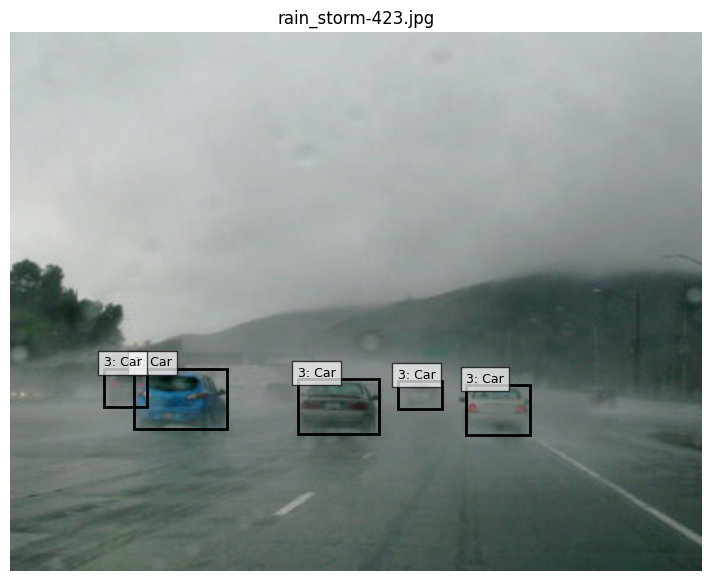

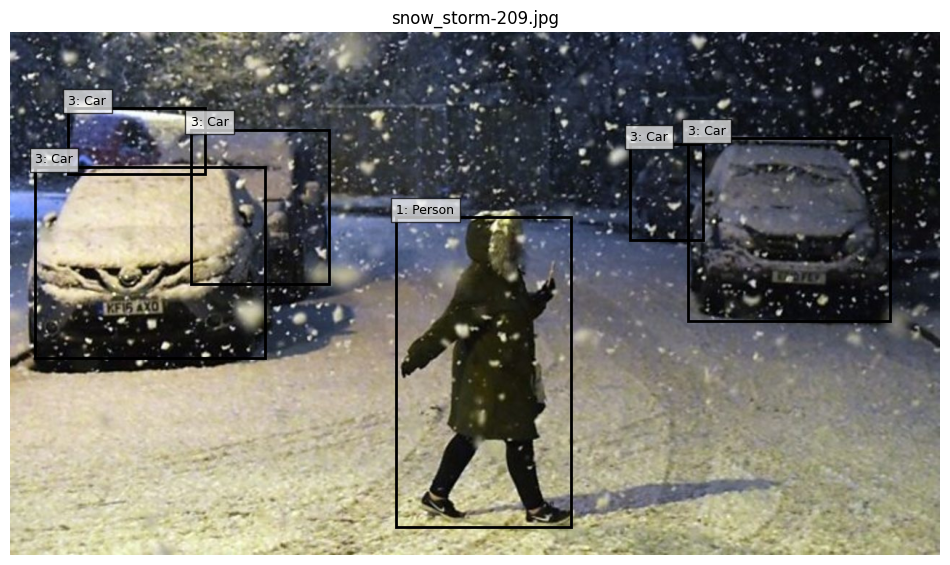

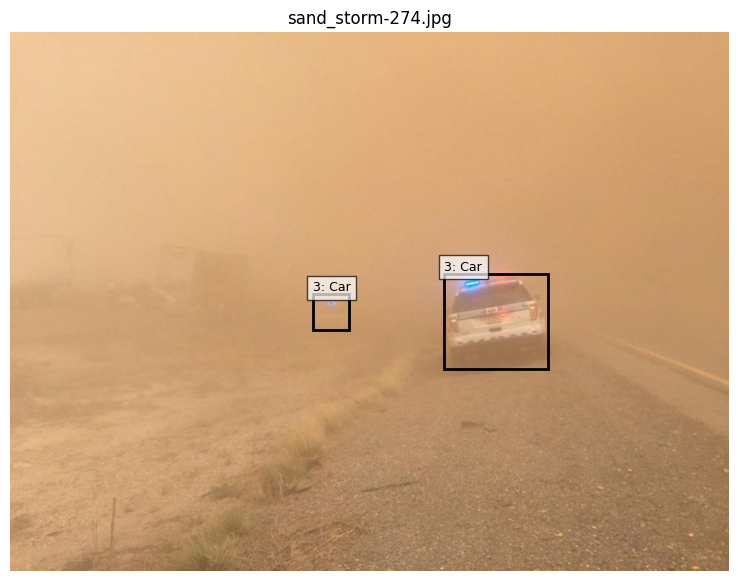

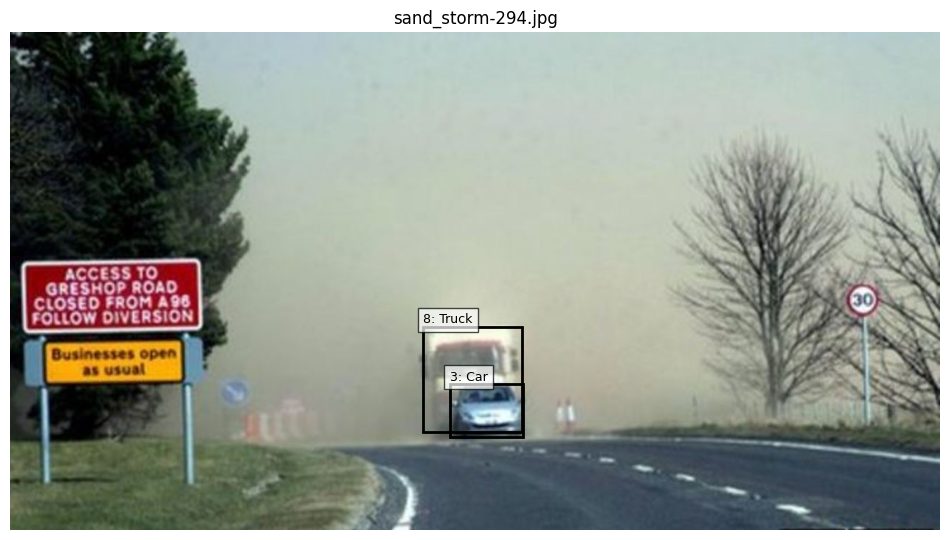

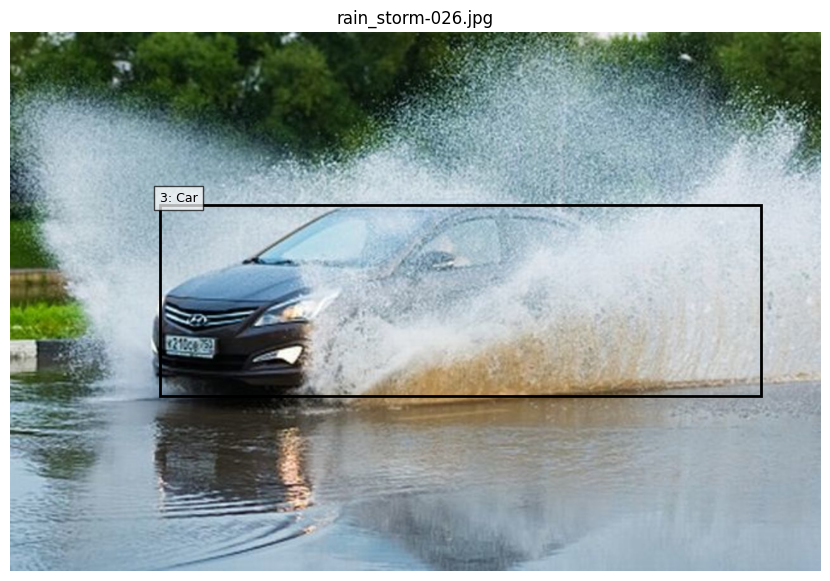

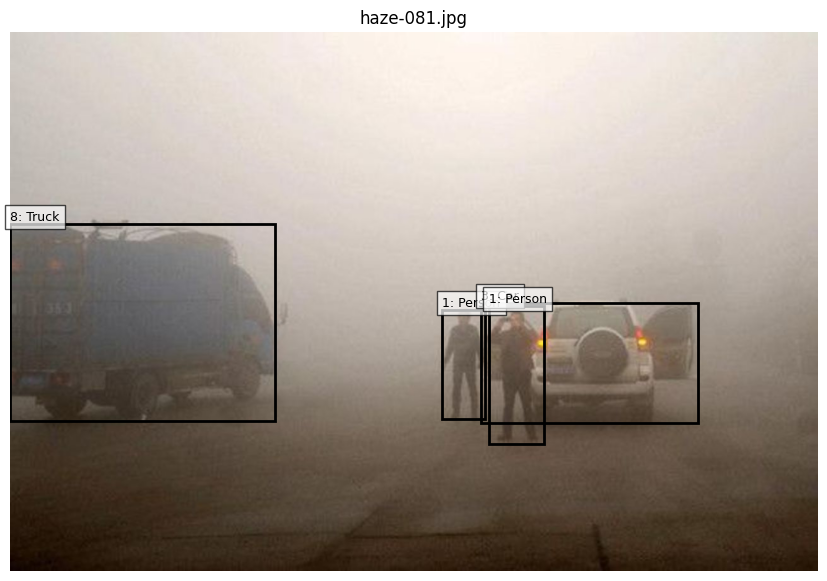

In [ ]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

raw_class_names = {
    1: "Person",
    2: "Bicycle",
    3: "Car",
    4: "Motorcycle",
    6: "Bus",
    7: "Unsupported / Inspect",
    8: "Truck"
}

random.seed(42)

sample_images = random.sample(image_files, 6)

for image_path in sample_images:

    label_path = label_dir / f"{image_path.stem}.txt"

    image = Image.open(image_path).convert("RGB")

    img_width, img_height = image.size

    fig, ax = plt.subplots(figsize=(12, 7))

    ax.imshow(image)

    if label_path.exists():

        lines = label_path.read_text().strip().splitlines()

        for line in lines:

            if not line.strip():
                continue

            class_id, x, y, w, h = map(float, line.split())

            class_id = int(class_id)

            # Convert YOLO normalized coordinates
            # to pixel coordinates

            box_width = w * img_width
            box_height = h * img_height

            x_min = (x * img_width) - box_width / 2
            y_min = (y * img_height) - box_height / 2

            rectangle = patches.Rectangle(
                (x_min, y_min),
                box_width,
                box_height,
                linewidth=2,
                fill=False
            )

            ax.add_patch(rectangle)

            label = raw_class_names.get(
                class_id,
                f"Unknown {class_id}"
            )

            ax.text(
                x_min,
                max(0, y_min - 5),
                f"{class_id}: {label}",
                fontsize=9,
                bbox=dict(facecolor="white", alpha=0.7)
            )

    ax.set_title(image_path.name)
    ax.axis("off")

    plt.show()

In [ ]:
print("EMPTY LABEL FILES:")
for name in empty_labels:
    print(name)

print("\nFILES CONTAINING CLASS 7:")

class7_occurrences = []

for label_file in label_dir.glob("*.txt"):

    text = label_file.read_text().strip()

    if not text:
        continue

    for line_number, line in enumerate(text.splitlines(), start=1):

        parts = line.split()

        if len(parts) != 5:
            continue

        class_id = int(float(parts[0]))

        if class_id == 7:
            class7_occurrences.append(
                (label_file.name, line_number, line)
            )

for item in class7_occurrences:
    print(item)

EMPTY LABEL FILES:
haze-012.txt

FILES CONTAINING CLASS 7:
('snow_storm-307.txt', 3, '7 0.3578125 0.5180555555555556 0.2484375 0.5277777777777778')


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

raw_class_names = {
    1: "Person",
    2: "Bicycle",
    3: "Car",
    4: "Motorcycle",
    6: "Bus",
    7: "ID 7 - INSPECT",
    8: "Truck"
}


def show_annotation(image_path, label_path):

    image = Image.open(image_path).convert("RGB")
    img_width, img_height = image.size

    fig, ax = plt.subplots(figsize=(14, 9))
    ax.imshow(image)

    if label_path.exists():

        text = label_path.read_text().strip()

        if text:

            for line in text.splitlines():

                class_id, x, y, w, h = map(float, line.split())
                class_id = int(class_id)

                box_width = w * img_width
                box_height = h * img_height

                x_min = x * img_width - box_width / 2
                y_min = y * img_height - box_height / 2

                rectangle = patches.Rectangle(
                    (x_min, y_min),
                    box_width,
                    box_height,
                    linewidth=2,
                    fill=False
                )

                ax.add_patch(rectangle)

                name = raw_class_names.get(
                    class_id,
                    f"Unknown {class_id}"
                )

                ax.text(
                    x_min,
                    max(0, y_min - 5),
                    f"{class_id}: {name}",
                    fontsize=10,
                    bbox=dict(
                        facecolor="white",
                        alpha=0.8
                    )
                )

    ax.set_title(image_path.name)
    ax.axis("off")
    plt.show()

EMPTY LABEL IMAGE: haze-012.jpg


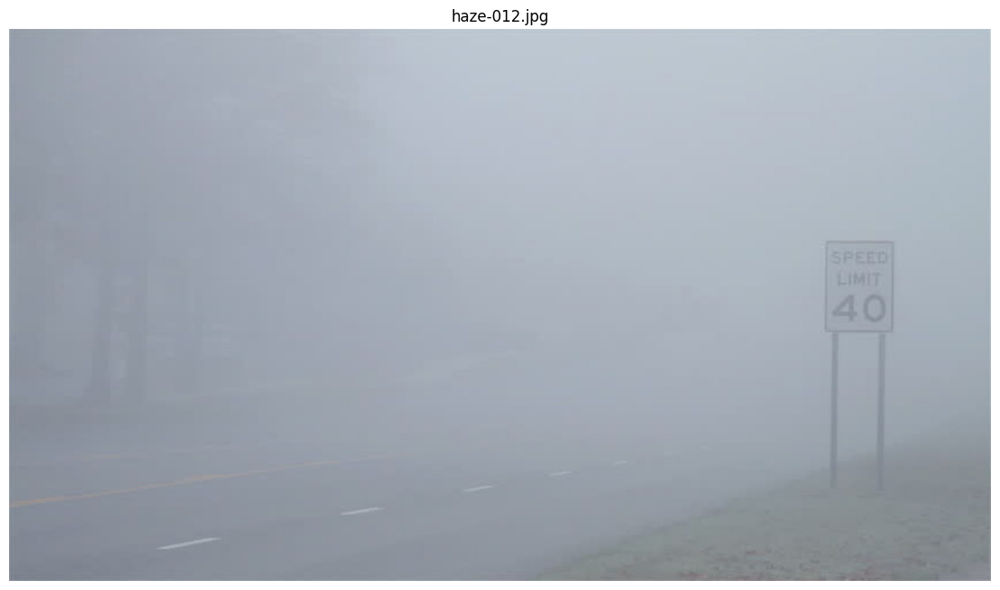

In [ ]:
# Show image belonging to the empty annotation

for empty_name in empty_labels:

    stem = Path(empty_name).stem

    matches = [
        p for p in image_files
        if p.stem == stem
    ]

    if matches:
        print("EMPTY LABEL IMAGE:", matches[0].name)

        show_annotation(
            matches[0],
            label_dir / empty_name
        )

CLASS 7 IMAGE: snow_storm-307.jpg
Suspicious annotation: 7 0.3578125 0.5180555555555556 0.2484375 0.5277777777777778


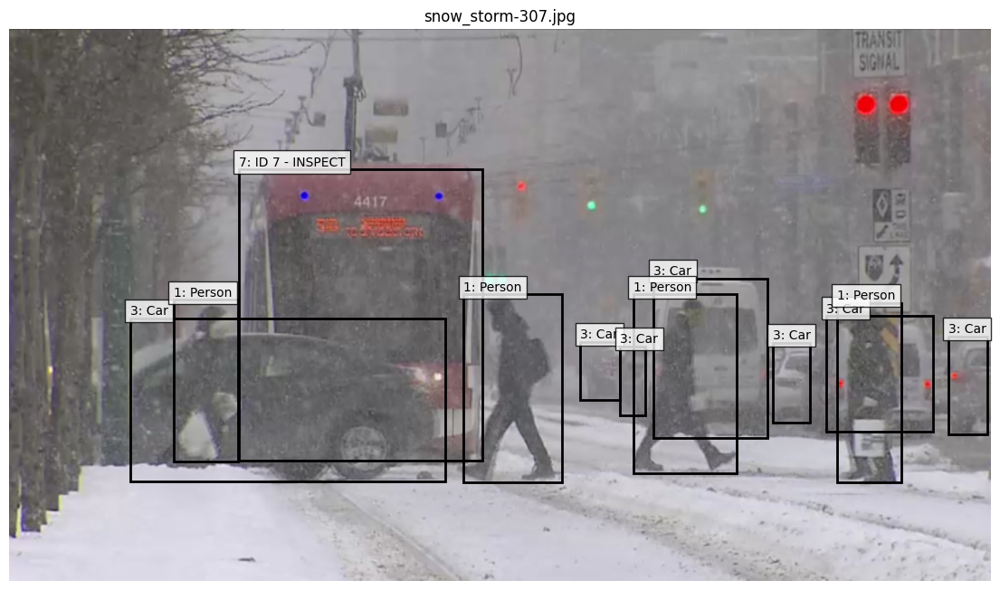

In [ ]:
# Show image containing class ID 7

for filename, line_number, line in class7_occurrences:

    stem = Path(filename).stem

    matches = [
        p for p in image_files
        if p.stem == stem
    ]

    if matches:
        print("CLASS 7 IMAGE:", matches[0].name)
        print("Suspicious annotation:", line)

        show_annotation(
            matches[0],
            label_dir / filename
        )

Image size: (1280, 721)


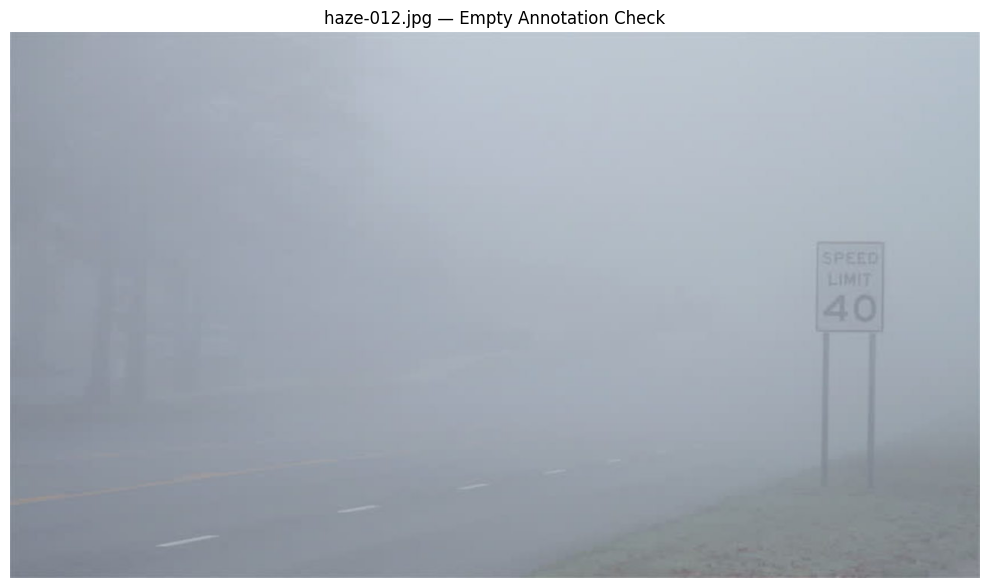

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img_path = image_dir / "haze-012.jpg"

img = Image.open(img_path).convert("RGB")

print("Image size:", img.size)

plt.figure(figsize=(10, 6))
plt.imshow(img)
plt.title("haze-012.jpg — Empty Annotation Check")
plt.axis("off")
plt.tight_layout()
plt.show()

## Step 7 — Create Clean DAWN Dataset

In [ ]:
# Original DAWN class IDs -> Clean YOLO class IDs

class_mapping = {
    1: 0,   # Person
    2: 1,   # Bicycle
    3: 2,   # Car
    4: 3,   # Motorcycle
    6: 4,   # Bus
    8: 5    # Truck
}

class_names_clean = {
    0: "Person",
    1: "Bicycle",
    2: "Car",
    3: "Motorcycle",
    4: "Bus",
    5: "Truck"
}

print("Clean class mapping:")

for old_id, new_id in class_mapping.items():
    print(
        f"Raw ID {old_id} -> "
        f"Clean ID {new_id}: {class_names_clean[new_id]}"
    )

Clean class mapping:
Raw ID 1 -> Clean ID 0: Person
Raw ID 2 -> Clean ID 1: Bicycle
Raw ID 3 -> Clean ID 2: Car
Raw ID 4 -> Clean ID 3: Motorcycle
Raw ID 6 -> Clean ID 4: Bus
Raw ID 8 -> Clean ID 5: Truck


In [ ]:
from pathlib import Path
import shutil

clean_root = Path("/content/dawn_clean")

clean_image_dir = clean_root / "images"
clean_label_dir = clean_root / "labels"

clean_image_dir.mkdir(parents=True, exist_ok=True)
clean_label_dir.mkdir(parents=True, exist_ok=True)

print("Clean dataset folder:", clean_root)

Clean dataset folder: /content/dawn_clean


In [ ]:
removed_annotations = []
copied_images = 0
created_labels = 0
kept_boxes = 0

for image_path in image_files:

    # Copy image
    destination_image = clean_image_dir / image_path.name

    shutil.copy2(
        image_path,
        destination_image
    )

    copied_images += 1

    # Original label
    original_label = label_dir / f"{image_path.stem}.txt"

    # New clean label
    clean_label = clean_label_dir / f"{image_path.stem}.txt"

    clean_lines = []

    if original_label.exists():

        text = original_label.read_text().strip()

        if text:

            for line_number, line in enumerate(
                text.splitlines(),
                start=1
            ):

                parts = line.split()

                if len(parts) != 5:
                    continue

                old_class = int(float(parts[0]))

                # Keep only our six target classes
                if old_class in class_mapping:

                    new_class = class_mapping[old_class]

                    new_line = " ".join(
                        [str(new_class)] + parts[1:]
                    )

                    clean_lines.append(new_line)
                    kept_boxes += 1

                else:

                    removed_annotations.append(
                        {
                            "file": original_label.name,
                            "line": line_number,
                            "class_id": old_class,
                            "annotation": line
                        }
                    )

    # Important:
    # Even if no boxes exist, create an empty .txt file.
    clean_label.write_text(
        "\n".join(clean_lines)
    )

    created_labels += 1

print("Images copied:", copied_images)
print("Label files created:", created_labels)
print("Target boxes kept:", kept_boxes)
print("Unsupported boxes removed:", len(removed_annotations))

print("\nRemoved annotations:")

for item in removed_annotations:
    print(item)

Images copied: 1027
Label files created: 1027
Target boxes kept: 7845
Unsupported boxes removed: 1

Removed annotations:
{'file': 'snow_storm-307.txt', 'line': 3, 'class_id': 7, 'annotation': '7 0.3578125 0.5180555555555556 0.2484375 0.5277777777777778'}


In [ ]:
from collections import Counter

clean_class_counts = Counter()

clean_total_boxes = 0
clean_empty_labels = []
clean_invalid_classes = []
clean_invalid_coordinates = []
clean_malformed_lines = []

for label_file in clean_label_dir.glob("*.txt"):

    text = label_file.read_text().strip()

    if not text:
        clean_empty_labels.append(label_file.name)
        continue

    for line_number, line in enumerate(
        text.splitlines(),
        start=1
    ):

        parts = line.split()

        if len(parts) != 5:

            clean_malformed_lines.append(
                (label_file.name, line_number, line)
            )

            continue

        try:
            class_id = int(parts[0])
            x, y, w, h = map(float, parts[1:])

        except ValueError:

            clean_malformed_lines.append(
                (label_file.name, line_number, line)
            )

            continue

        if class_id not in range(6):

            clean_invalid_classes.append(
                (label_file.name, line_number, class_id)
            )

        if not (
            0 <= x <= 1 and
            0 <= y <= 1 and
            0 < w <= 1 and
            0 < h <= 1
        ):

            clean_invalid_coordinates.append(
                (
                    label_file.name,
                    line_number,
                    x, y, w, h
                )
            )

        clean_class_counts[class_id] += 1
        clean_total_boxes += 1


print("CLEAN DATASET VALIDATION")
print("=" * 40)

print("Total boxes:", clean_total_boxes)
print("Empty label files:", len(clean_empty_labels))
print("Malformed lines:", len(clean_malformed_lines))
print("Invalid class IDs:", len(clean_invalid_classes))
print("Invalid coordinates:", len(clean_invalid_coordinates))

print("\nCLASS DISTRIBUTION:")

for class_id in range(6):

    count = clean_class_counts[class_id]

    percentage = (
        count / clean_total_boxes * 100
        if clean_total_boxes > 0
        else 0
    )

    print(
        f"{class_id} - {class_names_clean[class_id]}: "
        f"{count} ({percentage:.2f}%)"
    )

print("\nEmpty labels:")
print(clean_empty_labels)

CLEAN DATASET VALIDATION
Total boxes: 7845
Empty label files: 1
Malformed lines: 0
Invalid class IDs: 0
Invalid coordinates: 0

CLASS DISTRIBUTION:
0 - Person: 477 (6.08%)
1 - Bicycle: 26 (0.33%)
2 - Car: 6454 (82.27%)
3 - Motorcycle: 81 (1.03%)
4 - Bus: 161 (2.05%)
5 - Truck: 646 (8.23%)

Empty labels:
['haze-012.txt']


In [ ]:
clean_images = [
    p for p in clean_image_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
]

clean_labels = list(clean_label_dir.glob("*.txt"))

clean_image_stems = {p.stem for p in clean_images}
clean_label_stems = {p.stem for p in clean_labels}

print("Clean images:", len(clean_images))
print("Clean labels:", len(clean_labels))

print(
    "Images without labels:",
    len(clean_image_stems - clean_label_stems)
)

print(
    "Labels without images:",
    len(clean_label_stems - clean_image_stems)
)

Clean images: 1027
Clean labels: 1027
Images without labels: 0
Labels without images: 0


## Step 8 — Exploratory Data Analysis (EDA)


In [ ]:
from pathlib import Path

figure_dir = Path("/content/project_figures")
figure_dir.mkdir(parents=True, exist_ok=True)

print("Figures will be saved to:", figure_dir)

Figures will be saved to: /content/project_figures


In [ ]:
import pandas as pd

class_data = []

for class_id in range(6):

    count = clean_class_counts[class_id]
    percentage = count / clean_total_boxes * 100

    class_data.append({
        "Class ID": class_id,
        "Class": class_names_clean[class_id],
        "Objects": count,
        "Percentage": percentage
    })

class_df = pd.DataFrame(class_data)

class_df

,Class ID,Class,Objects,Percentage
0,0,Person,477,6.080306
1,1,Bicycle,26,0.331421
2,2,Car,6454,82.268961
3,3,Motorcycle,81,1.032505
4,4,Bus,161,2.052263
5,5,Truck,646,8.234544


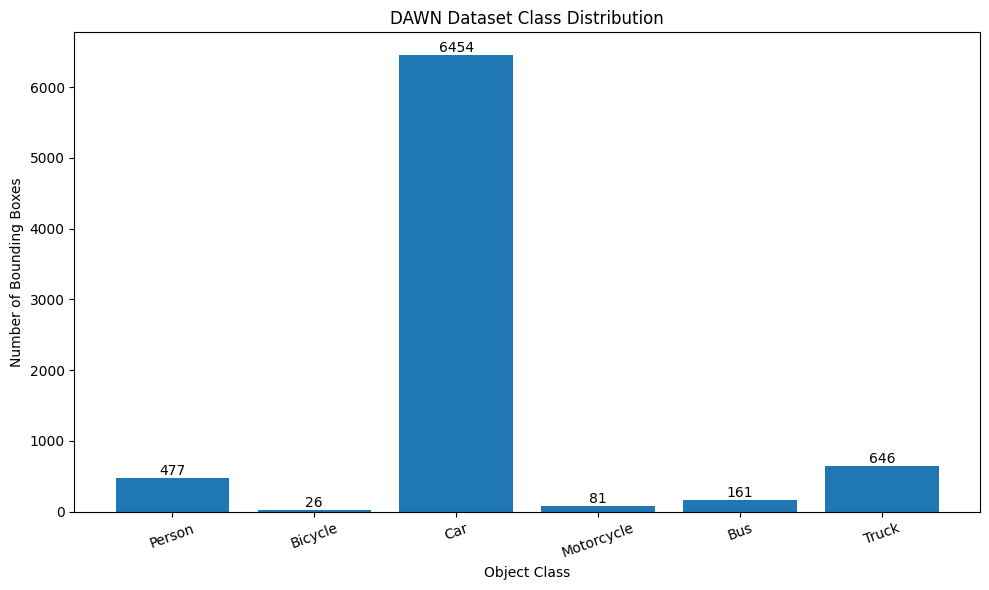

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

bars = plt.bar(
    class_df["Class"],
    class_df["Objects"]
)

plt.title("DAWN Dataset Class Distribution")
plt.xlabel("Object Class")
plt.ylabel("Number of Bounding Boxes")

plt.xticks(rotation=20)

for bar, count in zip(bars, class_df["Objects"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    figure_dir / "dawn_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

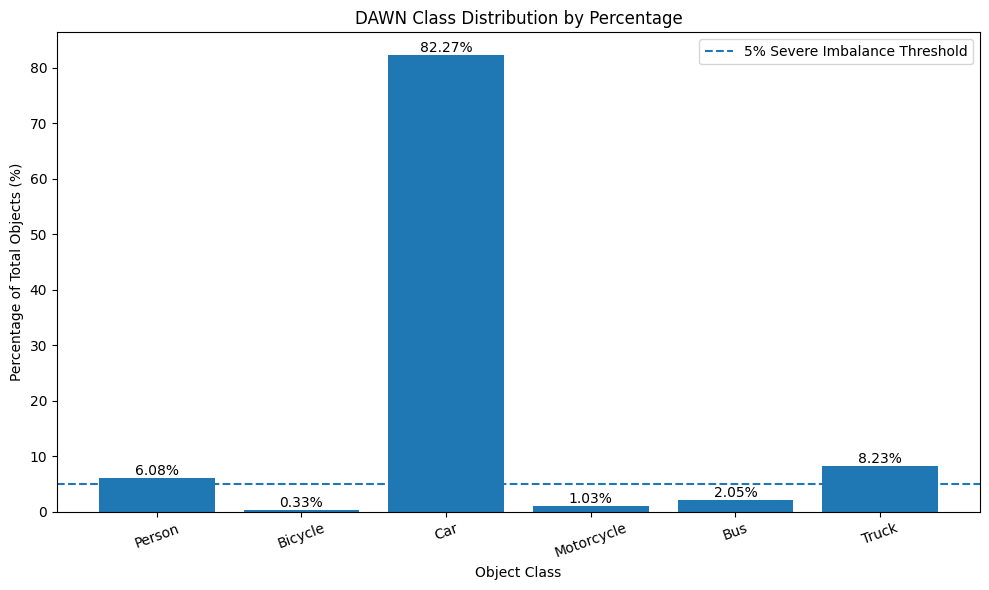

In [ ]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    class_df["Class"],
    class_df["Percentage"]
)

plt.axhline(
    y=5,
    linestyle="--",
    label="5% Severe Imbalance Threshold"
)

plt.title("DAWN Class Distribution by Percentage")
plt.xlabel("Object Class")
plt.ylabel("Percentage of Total Objects (%)")

plt.xticks(rotation=20)

for bar, percentage in zip(
    bars,
    class_df["Percentage"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percentage:.2f}%",
        ha="center",
        va="bottom"
    )

plt.legend()

plt.tight_layout()

plt.savefig(
    figure_dir / "dawn_class_percentage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
print("CLASS IMBALANCE ANALYSIS")
print("=" * 50)

for _, row in class_df.iterrows():

    percentage = row["Percentage"]

    if percentage < 5:
        category = "Severely underrepresented"

    elif percentage < 40:
        category = "Mildly represented"

    else:
        category = "Majority / highly represented"

    print(
        f"{row['Class']:12s}: "
        f"{percentage:6.2f}% -> {category}"
    )

CLASS IMBALANCE ANALYSIS
Person      :   6.08% -> Mildly represented
Bicycle     :   0.33% -> Severely underrepresented
Car         :  82.27% -> Majority / highly represented
Motorcycle  :   1.03% -> Severely underrepresented
Bus         :   2.05% -> Severely underrepresented
Truck       :   8.23% -> Mildly represented


In [ ]:
from collections import Counter

def get_weather(filename):

    name = filename.lower()

    if name.startswith(("haze", "foggy", "mist")):
        return "Fog"

    elif name.startswith("rain_storm"):
        return "Rain"

    elif name.startswith("snow_storm"):
        return "Snow"

    elif name.startswith(("sand_storm", "dusttornado")):
        return "Sandstorm"

    else:
        return "Unknown"


weather_counts = Counter()

for image_path in clean_images:

    weather = get_weather(image_path.name)
    weather_counts[weather] += 1


print("WEATHER DISTRIBUTION")
print("=" * 30)

for weather, count in weather_counts.items():
    print(f"{weather}: {count}")

print("\nTotal:", sum(weather_counts.values()))

WEATHER DISTRIBUTION
Fog: 300
Rain: 200
Sandstorm: 323
Snow: 204

Total: 1027


In [ ]:
weather_df = pd.DataFrame(
    [
        {
            "Weather": weather,
            "Images": count,
            "Percentage": count / len(clean_images) * 100
        }
        for weather, count in weather_counts.items()
    ]
)

weather_df = weather_df.sort_values(
    "Images",
    ascending=False
).reset_index(drop=True)

weather_df

,Weather,Images,Percentage
0,Sandstorm,323,31.450828
1,Fog,300,29.211295
2,Snow,204,19.863681
3,Rain,200,19.474197


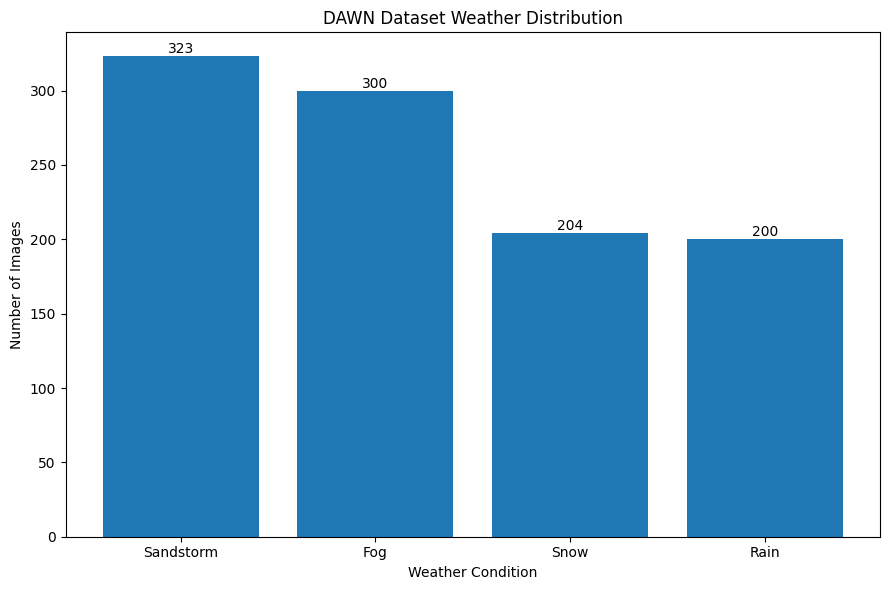

In [ ]:
plt.figure(figsize=(9, 6))

bars = plt.bar(
    weather_df["Weather"],
    weather_df["Images"]
)

plt.title("DAWN Dataset Weather Distribution")
plt.xlabel("Weather Condition")
plt.ylabel("Number of Images")

for bar, count in zip(
    bars,
    weather_df["Images"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    figure_dir / "dawn_weather_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
objects_per_image = []

for label_file in clean_label_dir.glob("*.txt"):

    text = label_file.read_text().strip()

    if not text:
        count = 0
    else:
        count = len(text.splitlines())

    objects_per_image.append(count)


objects_series = pd.Series(objects_per_image)

print("OBJECTS PER IMAGE")
print("=" * 40)

print(
    f"Minimum: {objects_series.min()}"
)

print(
    f"Maximum: {objects_series.max()}"
)

print(
    f"Mean: {objects_series.mean():.2f}"
)

print(
    f"Median: {objects_series.median():.2f}"
)

print(
    f"Images with zero target objects: "
    f"{(objects_series == 0).sum()}"
)

OBJECTS PER IMAGE
Minimum: 0
Maximum: 69
Mean: 7.64
Median: 5.00
Images with zero target objects: 1


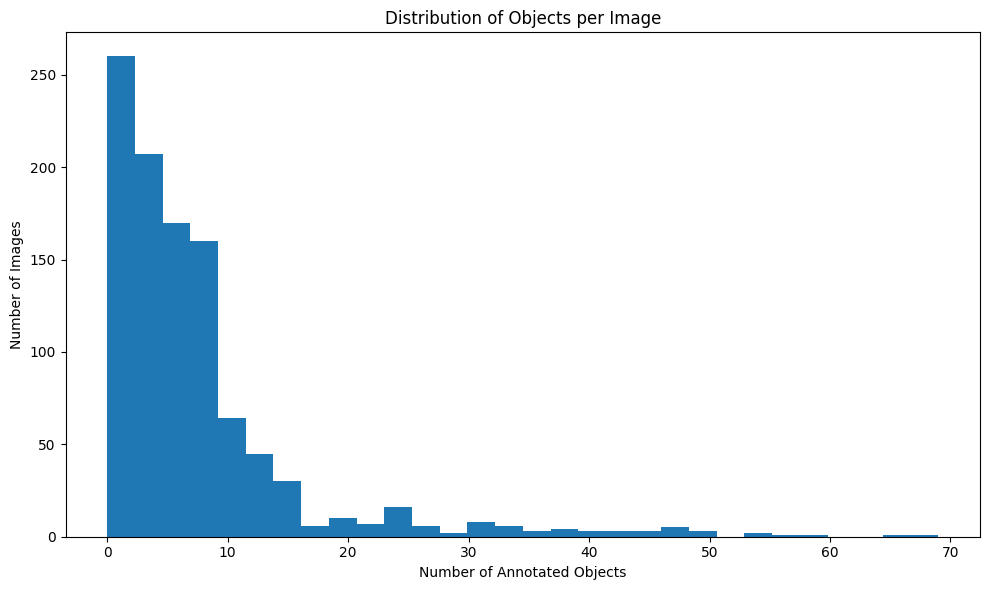

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(
    objects_per_image,
    bins=30
)

plt.title("Distribution of Objects per Image")
plt.xlabel("Number of Annotated Objects")
plt.ylabel("Number of Images")

plt.tight_layout()

plt.savefig(
    figure_dir / "dawn_objects_per_image.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
box_areas = []
box_widths = []
box_heights = []

box_areas_by_class = {
    class_id: []
    for class_id in range(6)
}

for label_file in clean_label_dir.glob("*.txt"):

    text = label_file.read_text().strip()

    if not text:
        continue

    for line in text.splitlines():

        class_id, x, y, w, h = map(
            float,
            line.split()
        )

        class_id = int(class_id)

        area = w * h

        box_widths.append(w)
        box_heights.append(h)
        box_areas.append(area)

        box_areas_by_class[class_id].append(area)


print("BOUNDING BOX ANALYSIS")
print("=" * 40)

print(f"Total boxes: {len(box_areas)}")

print(
    f"Average normalized width: "
    f"{sum(box_widths)/len(box_widths):.4f}"
)

print(
    f"Average normalized height: "
    f"{sum(box_heights)/len(box_heights):.4f}"
)

print(
    f"Average normalized area: "
    f"{sum(box_areas)/len(box_areas):.4f}"
)

BOUNDING BOX ANALYSIS
Total boxes: 7845
Average normalized width: 0.0962
Average normalized height: 0.1377
Average normalized area: 0.0211


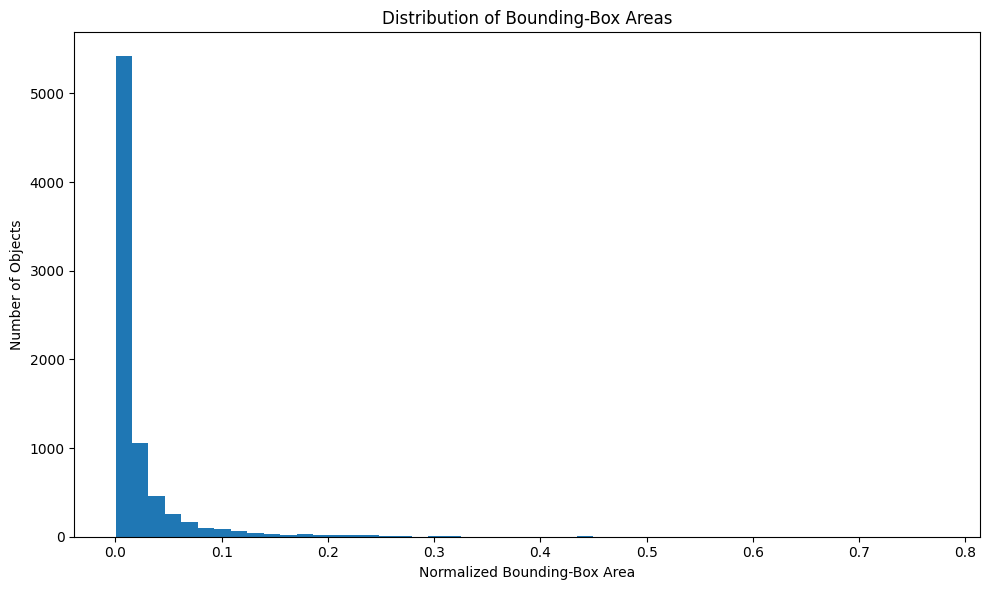

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(
    box_areas,
    bins=50
)

plt.title("Distribution of Bounding-Box Areas")
plt.xlabel("Normalized Bounding-Box Area")
plt.ylabel("Number of Objects")

plt.tight_layout()

plt.savefig(
    figure_dir / "dawn_bbox_area_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from collections import defaultdict

weather_class_counts = defaultdict(
    lambda: {class_id: 0 for class_id in range(6)}
)

for image_path in clean_images:

    weather = get_weather(image_path.name)

    label_path = clean_label_dir / f"{image_path.stem}.txt"

    if not label_path.exists():
        continue

    text = label_path.read_text().strip()

    if not text:
        continue

    for line in text.splitlines():

        parts = line.split()

        class_id = int(parts[0])

        weather_class_counts[weather][class_id] += 1


for weather in ["Fog", "Rain", "Snow", "Sandstorm"]:

    print(f"\n{weather}")
    print("-" * 30)

    total = sum(weather_class_counts[weather].values())

    for class_id in range(6):

        count = weather_class_counts[weather][class_id]

        percentage = (
            count / total * 100
            if total > 0
            else 0
        )

        print(
            f"{class_names_clean[class_id]:12s}: "
            f"{count:5d} ({percentage:6.2f}%)"
        )

    print("Total objects:", total)


Fog
------------------------------
Person      :   117 (  6.00%)
Bicycle     :    16 (  0.82%)
Car         :  1570 ( 80.47%)
Motorcycle  :    23 (  1.18%)
Bus         :    71 (  3.64%)
Truck       :   154 (  7.89%)
Total objects: 1951

Rain
------------------------------
Person      :    28 (  1.76%)
Bicycle     :     0 (  0.00%)
Car         :  1355 ( 85.33%)
Motorcycle  :     4 (  0.25%)
Bus         :    13 (  0.82%)
Truck       :   188 ( 11.84%)
Total objects: 1588

Snow
------------------------------
Person      :   158 (  7.63%)
Bicycle     :     1 (  0.05%)
Car         :  1781 ( 86.00%)
Motorcycle  :     1 (  0.05%)
Bus         :    22 (  1.06%)
Truck       :   108 (  5.21%)
Total objects: 2071

Sandstorm
------------------------------
Person      :   174 (  7.79%)
Bicycle     :     9 (  0.40%)
Car         :  1748 ( 78.21%)
Motorcycle  :    53 (  2.37%)
Bus         :    55 (  2.46%)
Truck       :   196 (  8.77%)
Total objects: 2235


In [ ]:
weather_class_data = []

for weather in ["Fog", "Rain", "Snow", "Sandstorm"]:

    row = {
        "Weather": weather
    }

    for class_id in range(6):

        row[class_names_clean[class_id]] = (
            weather_class_counts[weather][class_id]
        )

    row["Total Objects"] = sum(
        weather_class_counts[weather].values()
    )

    weather_class_data.append(row)


weather_class_df = pd.DataFrame(weather_class_data)

weather_class_df

,Weather,Person,Bicycle,Car,Motorcycle,Bus,Truck,Total Objects
0,Fog,117,16,1570,23,71,154,1951
1,Rain,28,0,1355,4,13,188,1588
2,Snow,158,1,1781,1,22,108,2071
3,Sandstorm,174,9,1748,53,55,196,2235


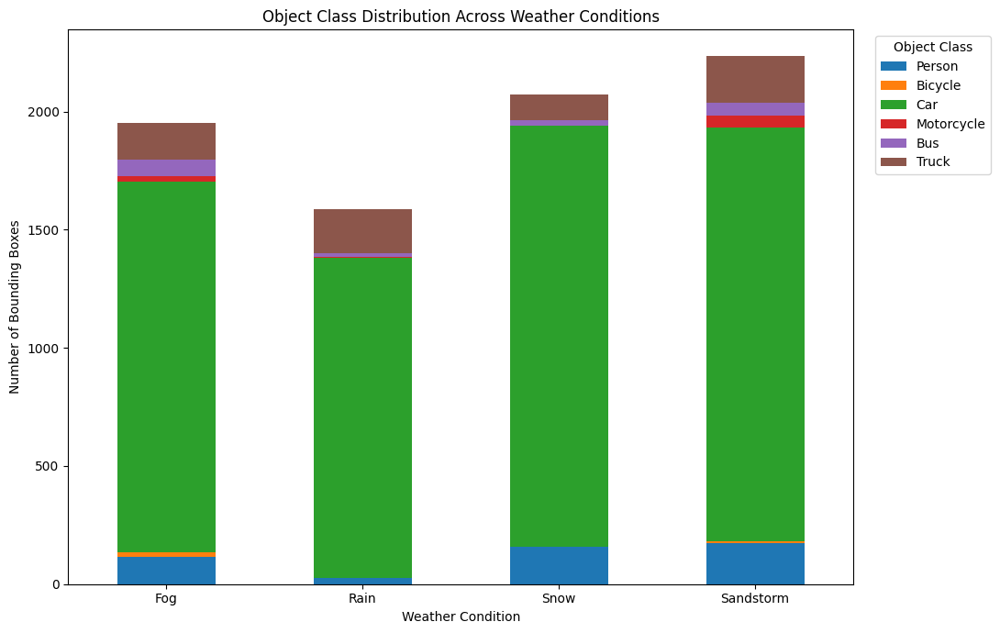

In [ ]:
plot_df = weather_class_df.set_index("Weather")[
    [
        "Person",
        "Bicycle",
        "Car",
        "Motorcycle",
        "Bus",
        "Truck"
    ]
]

ax = plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 7)
)

plt.title("Object Class Distribution Across Weather Conditions")
plt.xlabel("Weather Condition")
plt.ylabel("Number of Bounding Boxes")

plt.xticks(rotation=0)

plt.legend(
    title="Object Class",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    figure_dir / "dawn_classes_by_weather.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
weather_percentage_df = plot_df.div(
    plot_df.sum(axis=1),
    axis=0
) * 100

weather_percentage_df.round(2)

,Person,Bicycle,Car,Motorcycle,Bus,Truck
Weather,,,,,,
Fog,6.00,0.82,80.47,1.18,3.64,7.89
Rain,1.76,0.00,85.33,0.25,0.82,11.84
Snow,7.63,0.05,86.00,0.05,1.06,5.21
Sandstorm,7.79,0.40,78.21,2.37,2.46,8.77


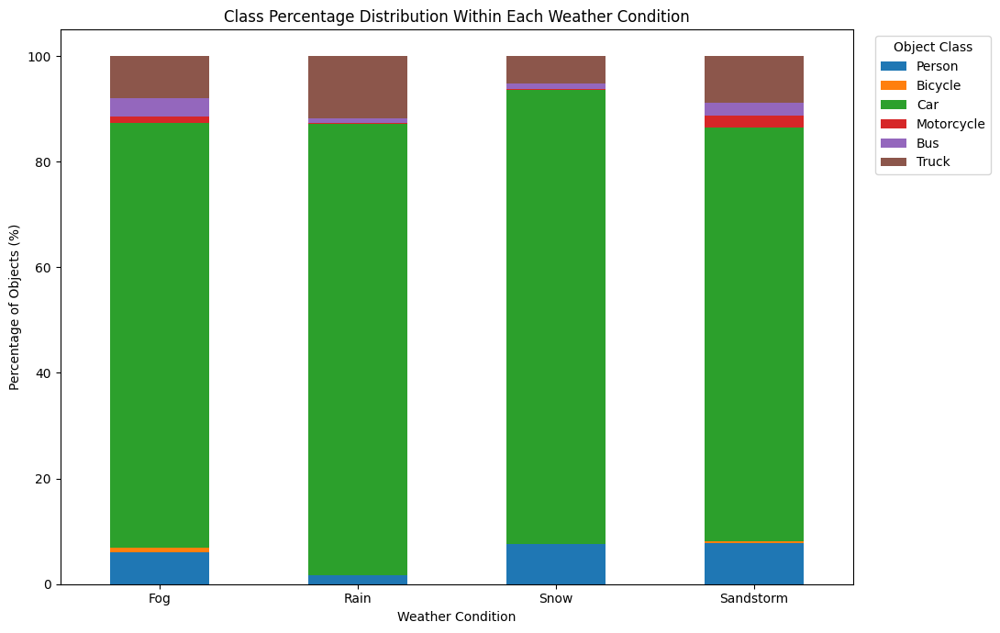

In [ ]:
ax = weather_percentage_df.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 7)
)

plt.title(
    "Class Percentage Distribution Within Each Weather Condition"
)

plt.xlabel("Weather Condition")
plt.ylabel("Percentage of Objects (%)")

plt.xticks(rotation=0)

plt.legend(
    title="Object Class",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    figure_dir / "dawn_class_percentage_by_weather.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
weather_object_total = weather_class_df[
    "Total Objects"
].sum()

print("Total objects from weather analysis:", weather_object_total)
print("Expected clean objects:", clean_total_boxes)

if weather_object_total == clean_total_boxes:
    print("PASS — all objects are accounted for.")
else:
    print("WARNING — totals do not match.")

Total objects from weather analysis: 7845
Expected clean objects: 7845
PASS — all objects are accounted for.


## Step 9 — Train, Validation, and Test Split



In [ ]:
!pip -q install iterative-stratification

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

records = []

weather_names = ["Fog", "Rain", "Snow", "Sandstorm"]

for image_path in clean_images:

    label_path = clean_label_dir / f"{image_path.stem}.txt"

    # Track whether each class is present in this image
    class_presence = [0] * 6

    if label_path.exists():

        text = label_path.read_text().strip()

        if text:

            for line in text.splitlines():

                class_id = int(line.split()[0])

                if 0 <= class_id < 6:
                    class_presence[class_id] = 1

    weather = get_weather(image_path.name)

    record = {
        "image_name": image_path.name,
        "image_path": str(image_path),
        "label_path": str(label_path),
        "weather": weather
    }

    # Add class-presence columns
    for class_id in range(6):
        record[f"class_{class_id}"] = class_presence[class_id]

    # Add weather-presence columns
    for weather_name in weather_names:
        record[f"weather_{weather_name}"] = int(
            weather == weather_name
        )

    records.append(record)


split_df = pd.DataFrame(records)

print("Total images:", len(split_df))

split_df.head()

Total images: 1027


,image_name,image_path,label_path,weather,class_0,class_1,class_2,class_3,class_4,class_5,weather_Fog,weather_Rain,weather_Snow,weather_Sandstorm
0,foggy-033.jpg,/content/dawn_clean/images/foggy-033.jpg,/content/dawn_clean/labels/foggy-033.txt,Fog,0,0,1,0,0,1,1,0,0,0
1,foggy-067.jpg,/content/dawn_clean/images/foggy-067.jpg,/content/dawn_clean/labels/foggy-067.txt,Fog,0,0,1,0,0,0,1,0,0,0
2,rain_storm-443.jpg,/content/dawn_clean/images/rain_storm-443.jpg,/content/dawn_clean/labels/rain_storm-443.txt,Rain,0,0,1,0,0,0,0,1,0,0
3,rain_storm-654.jpg,/content/dawn_clean/images/rain_storm-654.jpg,/content/dawn_clean/labels/rain_storm-654.txt,Rain,0,0,1,0,0,0,0,1,0,0
4,rain_storm-523.jpg,/content/dawn_clean/images/rain_storm-523.jpg,/content/dawn_clean/labels/rain_storm-523.txt,Rain,0,0,1,0,0,1,0,1,0,0


In [ ]:
print("IMAGE-LEVEL CLASS PRESENCE")
print("=" * 50)

for class_id in range(6):

    count = split_df[f"class_{class_id}"].sum()

    print(
        f"{class_id} - {class_names_clean[class_id]:12s}: "
        f"{count} images"
    )

print("\nWEATHER IMAGE COUNTS")
print("=" * 50)

print(split_df["weather"].value_counts())

IMAGE-LEVEL CLASS PRESENCE
0 - Person      : 210 images
1 - Bicycle     : 20 images
2 - Car         : 1010 images
3 - Motorcycle  : 46 images
4 - Bus         : 106 images
5 - Truck       : 308 images

WEATHER IMAGE COUNTS
weather
Sandstorm    323
Fog          300
Snow         204
Rain         200
Name: count, dtype: int64


In [ ]:
stratification_columns = [
    "class_0",
    "class_1",
    "class_2",
    "class_3",
    "class_4",
    "class_5",
    "weather_Fog",
    "weather_Rain",
    "weather_Snow",
    "weather_Sandstorm"
]

X = np.arange(len(split_df)).reshape(-1, 1)

y = split_df[stratification_columns].values

print("Images:", X.shape[0])
print("Stratification features:", y.shape[1])

Images: 1027
Stratification features: 10


In [ ]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

SEED = 42

first_split = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=SEED
)

train_idx, temp_idx = next(
    first_split.split(X, y)
)

train_df = split_df.iloc[train_idx].copy()
temp_df = split_df.iloc[temp_idx].copy()

print("Train images:", len(train_df))
print("Temporary images:", len(temp_df))
print("Total:", len(train_df) + len(temp_df))

Train images: 715
Temporary images: 312
Total: 1027


In [ ]:
X_temp = np.arange(len(temp_df)).reshape(-1, 1)

y_temp = temp_df[
    stratification_columns
].values

second_split = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=SEED
)

val_local_idx, test_local_idx = next(
    second_split.split(
        X_temp,
        y_temp
    )
)

val_df = temp_df.iloc[val_local_idx].copy()
test_df = temp_df.iloc[test_local_idx].copy()

print("FINAL SPLIT")
print("=" * 40)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print(
    "Total:",
    len(train_df) +
    len(val_df) +
    len(test_df)
)

FINAL SPLIT
Train: 715
Validation: 156
Test: 156
Total: 1027


In [ ]:
total_images = len(split_df)

print("SPLIT PERCENTAGES")
print("=" * 40)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:

    percentage = len(df) / total_images * 100

    print(
        f"{name:12s}: "
        f"{len(df):4d} images "
        f"({percentage:.2f}%)"
    )

SPLIT PERCENTAGES
Train       :  715 images (69.62%)
Validation  :  156 images (15.19%)
Test        :  156 images (15.19%)


In [ ]:
train_names = set(train_df["image_name"])
val_names = set(val_df["image_name"])
test_names = set(test_df["image_name"])

train_val_overlap = train_names & val_names
train_test_overlap = train_names & test_names
val_test_overlap = val_names & test_names

print("DATA LEAKAGE CHECK")
print("=" * 40)

print(
    "Train / Validation overlap:",
    len(train_val_overlap)
)

print(
    "Train / Test overlap:",
    len(train_test_overlap)
)

print(
    "Validation / Test overlap:",
    len(val_test_overlap)
)

DATA LEAKAGE CHECK
Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0


In [ ]:
weather_split_table = pd.DataFrame({
    "Full Dataset":
        split_df["weather"].value_counts(),

    "Train":
        train_df["weather"].value_counts(),

    "Validation":
        val_df["weather"].value_counts(),

    "Test":
        test_df["weather"].value_counts()
}).fillna(0).astype(int)

weather_split_table

,Full Dataset,Train,Validation,Test
weather,,,,
Fog,300,206,47,47
Rain,200,140,30,30
Sandstorm,323,226,49,48
Snow,204,143,30,31


In [ ]:
class_split_data = []

for class_id in range(6):

    column = f"class_{class_id}"

    class_split_data.append({
        "Class": class_names_clean[class_id],

        "Full Dataset":
            int(split_df[column].sum()),

        "Train":
            int(train_df[column].sum()),

        "Validation":
            int(val_df[column].sum()),

        "Test":
            int(test_df[column].sum())
    })


class_split_table = pd.DataFrame(
    class_split_data
)

class_split_table

,Class,Full Dataset,Train,Validation,Test
0,Person,210,147,32,31
1,Bicycle,20,14,3,3
2,Car,1010,706,153,151
3,Motorcycle,46,32,7,7
4,Bus,106,74,16,16
5,Truck,308,215,47,46


In [ ]:
from collections import Counter


def count_split_boxes(df):

    counts = Counter()

    for label_path_str in df["label_path"]:

        label_path = Path(label_path_str)

        text = label_path.read_text().strip()

        if not text:
            continue

        for line in text.splitlines():

            class_id = int(
                line.split()[0]
            )

            counts[class_id] += 1

    return counts


train_box_counts = count_split_boxes(train_df)
val_box_counts = count_split_boxes(val_df)
test_box_counts = count_split_boxes(test_df)


box_split_data = []

for class_id in range(6):

    box_split_data.append({
        "Class": class_names_clean[class_id],

        "Full":
            clean_class_counts[class_id],

        "Train":
            train_box_counts[class_id],

        "Validation":
            val_box_counts[class_id],

        "Test":
            test_box_counts[class_id]
    })


box_split_table = pd.DataFrame(
    box_split_data
)

box_split_table

,Class,Full,Train,Validation,Test
0,Person,477,308,102,67
1,Bicycle,26,16,6,4
2,Car,6454,4377,1050,1027
3,Motorcycle,81,60,13,8
4,Bus,161,114,28,19
5,Truck,646,420,107,119


In [ ]:
print("BOUNDING BOX TOTAL CHECK")
print("=" * 40)

print(
    "Train boxes:",
    sum(train_box_counts.values())
)

print(
    "Validation boxes:",
    sum(val_box_counts.values())
)

print(
    "Test boxes:",
    sum(test_box_counts.values())
)

all_split_boxes = (
    sum(train_box_counts.values()) +
    sum(val_box_counts.values()) +
    sum(test_box_counts.values())
)

print("\nCombined:", all_split_boxes)
print("Expected:", clean_total_boxes)

if all_split_boxes == clean_total_boxes:

    print(
        "\nPASS — all 7,845 bounding boxes "
        "are accounted for."
    )

else:

    print(
        "\nWARNING — bounding box totals "
        "do not match."
    )

BOUNDING BOX TOTAL CHECK
Train boxes: 5295
Validation boxes: 1306
Test boxes: 1244

Combined: 7845
Expected: 7845

PASS — all 7,845 bounding boxes are accounted for.


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

TARGET = np.array([0.70, 0.15, 0.15])

# ---------------------------------------------------------
# 1. Pre-compute number of boxes of each class in every image
# ---------------------------------------------------------

image_box_counts = np.zeros(
    (len(split_df), 6),
    dtype=int
)

for i, label_path_str in enumerate(split_df["label_path"]):

    label_path = Path(label_path_str)

    text = label_path.read_text().strip()

    if not text:
        continue

    for line in text.splitlines():

        class_id = int(line.split()[0])

        if 0 <= class_id < 6:
            image_box_counts[i, class_id] += 1


# ---------------------------------------------------------
# 2. Function to create one 70/15/15 split
# ---------------------------------------------------------

def make_split(seed):

    X_all = np.arange(len(split_df)).reshape(-1, 1)

    y_all = split_df[
        stratification_columns
    ].values

    # First split: 70% train, 30% temporary
    first_split = MultilabelStratifiedShuffleSplit(
        n_splits=1,
        test_size=0.30,
        random_state=seed
    )

    train_idx, temp_idx = next(
        first_split.split(X_all, y_all)
    )

    # Second split: temporary -> 15% validation + 15% test
    X_temp = np.arange(len(temp_idx)).reshape(-1, 1)

    y_temp = y_all[temp_idx]

    second_split = MultilabelStratifiedShuffleSplit(
        n_splits=1,
        test_size=0.50,
        random_state=seed
    )

    val_local_idx, test_local_idx = next(
        second_split.split(X_temp, y_temp)
    )

    val_idx = temp_idx[val_local_idx]
    test_idx = temp_idx[test_local_idx]

    return train_idx, val_idx, test_idx


# ---------------------------------------------------------
# 3. Score how well a split preserves distributions
# ---------------------------------------------------------

def ratio_error(split_counts, total_counts):

    errors = []

    for j in range(len(total_counts)):

        total = total_counts[j]

        if total == 0:
            continue

        ratios = np.array([
            split_counts[0][j] / total,
            split_counts[1][j] / total,
            split_counts[2][j] / total
        ])

        errors.append(
            np.mean(np.abs(ratios - TARGET))
        )

    return np.mean(errors)


def evaluate_seed(seed):

    train_idx, val_idx, test_idx = make_split(seed)

    indices = [
        train_idx,
        val_idx,
        test_idx
    ]

    # ---------------------------------
    # Bounding-box distribution
    # ---------------------------------

    box_split_counts = [
        image_box_counts[idx].sum(axis=0)
        for idx in indices
    ]

    total_box_counts = image_box_counts.sum(axis=0)

    box_error = ratio_error(
        box_split_counts,
        total_box_counts
    )

    # ---------------------------------
    # Image-level class presence
    # ---------------------------------

    class_matrix = split_df[
        [f"class_{i}" for i in range(6)]
    ].values

    class_split_counts = [
        class_matrix[idx].sum(axis=0)
        for idx in indices
    ]

    total_class_counts = class_matrix.sum(axis=0)

    class_error = ratio_error(
        class_split_counts,
        total_class_counts
    )

    # ---------------------------------
    # Weather distribution
    # ---------------------------------

    weather_matrix = split_df[
        [
            "weather_Fog",
            "weather_Rain",
            "weather_Snow",
            "weather_Sandstorm"
        ]
    ].values

    weather_split_counts = [
        weather_matrix[idx].sum(axis=0)
        for idx in indices
    ]

    total_weather_counts = weather_matrix.sum(axis=0)

    weather_error = ratio_error(
        weather_split_counts,
        total_weather_counts
    )

    # ---------------------------------
    # Make sure every class appears
    # in validation and test
    # ---------------------------------

    val_class_presence = class_split_counts[1]
    test_class_presence = class_split_counts[2]

    if np.any(val_class_presence == 0):
        return None

    if np.any(test_class_presence == 0):
        return None

    # Bounding-box balance gets highest importance
    score = (
        0.60 * box_error +
        0.25 * class_error +
        0.15 * weather_error
    )

    return {
        "seed": seed,
        "score": score,
        "box_error": box_error,
        "class_error": class_error,
        "weather_error": weather_error,
        "train_idx": train_idx,
        "val_idx": val_idx,
        "test_idx": test_idx
    }


# ---------------------------------------------------------
# 4. Test many seeds
# ---------------------------------------------------------

results = []

for seed in range(500):

    result = evaluate_seed(seed)

    if result is not None:
        results.append(result)


results = sorted(
    results,
    key=lambda x: x["score"]
)

best = results[0]

print("BEST SPLIT FOUND")
print("=" * 50)

print("Best seed:", best["seed"])
print(f"Overall balance score: {best['score']:.6f}")
print(f"Bounding-box error:    {best['box_error']:.6f}")
print(f"Class-presence error:  {best['class_error']:.6f}")
print(f"Weather error:         {best['weather_error']:.6f}")


# ---------------------------------------------------------
# 5. LOCK the best split
# ---------------------------------------------------------

BEST_SEED = best["seed"]

train_df = split_df.iloc[
    best["train_idx"]
].copy()

val_df = split_df.iloc[
    best["val_idx"]
].copy()

test_df = split_df.iloc[
    best["test_idx"]
].copy()


print("\nFINAL LOCKED SPLIT")
print("=" * 50)

print(
    f"Train:      {len(train_df)} "
    f"({len(train_df)/len(split_df)*100:.2f}%)"
)

print(
    f"Validation: {len(val_df)} "
    f"({len(val_df)/len(split_df)*100:.2f}%)"
)

print(
    f"Test:       {len(test_df)} "
    f"({len(test_df)/len(split_df)*100:.2f}%)"
)

print(
    "Total:",
    len(train_df) +
    len(val_df) +
    len(test_df)
)

BEST SPLIT FOUND
Best seed: 306
Overall balance score: 0.007092
Bounding-box error:    0.010922
Class-presence error:  0.001356
Weather error:         0.001330

FINAL LOCKED SPLIT
Train:      718 (69.91%)
Validation: 154 (15.00%)
Test:       155 (15.09%)
Total: 1027


In [ ]:
# Recalculate bounding-box counts for the optimized split

train_box_counts = count_split_boxes(train_df)
val_box_counts = count_split_boxes(val_df)
test_box_counts = count_split_boxes(test_df)

optimized_box_table = pd.DataFrame([
    {
        "Class": class_names_clean[class_id],
        "Full": clean_class_counts[class_id],
        "Train": train_box_counts[class_id],
        "Validation": val_box_counts[class_id],
        "Test": test_box_counts[class_id]
    }
    for class_id in range(6)
])

print("BOUNDING-BOX DISTRIBUTION")
display(optimized_box_table)


print("\nWEATHER DISTRIBUTION")

optimized_weather_table = pd.DataFrame({
    "Full": split_df["weather"].value_counts(),
    "Train": train_df["weather"].value_counts(),
    "Validation": val_df["weather"].value_counts(),
    "Test": test_df["weather"].value_counts()
}).fillna(0).astype(int)

display(optimized_weather_table)


print("\nDATA LEAKAGE CHECK")

train_names = set(train_df["image_name"])
val_names = set(val_df["image_name"])
test_names = set(test_df["image_name"])

print(
    "Train / Validation overlap:",
    len(train_names & val_names)
)

print(
    "Train / Test overlap:",
    len(train_names & test_names)
)

print(
    "Validation / Test overlap:",
    len(val_names & test_names)
)


all_boxes = (
    sum(train_box_counts.values()) +
    sum(val_box_counts.values()) +
    sum(test_box_counts.values())
)

print("\nBOUNDING-BOX TOTAL CHECK")
print("Combined:", all_boxes)
print("Expected:", clean_total_boxes)

if all_boxes == clean_total_boxes:
    print("PASS — all bounding boxes are accounted for.")
else:
    print("WARNING — totals do not match.")

BOUNDING-BOX DISTRIBUTION


,Class,Full,Train,Validation,Test
0,Person,477,335,73,69
1,Bicycle,26,18,4,4
2,Car,6454,4558,1031,865
3,Motorcycle,81,58,12,11
4,Bus,161,120,20,21
5,Truck,646,451,93,102



WEATHER DISTRIBUTION


,Full,Train,Validation,Test
weather,,,,
Fog,300,209,45,46
Rain,200,140,30,30
Sandstorm,323,226,49,48
Snow,204,143,30,31



DATA LEAKAGE CHECK
Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0

BOUNDING-BOX TOTAL CHECK
Combined: 7845
Expected: 7845
PASS — all bounding boxes are accounted for.


## Step 10 — Build Final YOLO Dataset



In [ ]:
from pathlib import Path
import shutil

yolo_root = Path("/content/dawn_yolo")

folders = [
    yolo_root / "images" / "train",
    yolo_root / "images" / "val",
    yolo_root / "images" / "test",

    yolo_root / "labels" / "train",
    yolo_root / "labels" / "val",
    yolo_root / "labels" / "test"
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

print("YOLO dataset root:", yolo_root)

YOLO dataset root: /content/dawn_yolo


In [ ]:
def copy_split(df, split_name):

    image_destination = yolo_root / "images" / split_name
    label_destination = yolo_root / "labels" / split_name

    copied_images = 0
    copied_labels = 0

    for _, row in df.iterrows():

        source_image = Path(row["image_path"])
        source_label = Path(row["label_path"])

        shutil.copy2(
            source_image,
            image_destination / source_image.name
        )

        shutil.copy2(
            source_label,
            label_destination / source_label.name
        )

        copied_images += 1
        copied_labels += 1

    print(
        f"{split_name}: "
        f"{copied_images} images, "
        f"{copied_labels} labels"
    )


copy_split(train_df, "train")
copy_split(val_df, "val")
copy_split(test_df, "test")

train: 718 images, 718 labels
val: 154 images, 154 labels
test: 155 images, 155 labels


In [ ]:
import yaml

data_yaml = {
    "path": str(yolo_root),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",

    "names": {
        0: "Person",
        1: "Bicycle",
        2: "Car",
        3: "Motorcycle",
        4: "Bus",
        5: "Truck"
    }
}

yaml_path = yolo_root / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.dump(
        data_yaml,
        f,
        sort_keys=False
    )

print(yaml_path.read_text())

path: /content/dawn_yolo
train: images/train
val: images/val
test: images/test
names:
  0: Person
  1: Bicycle
  2: Car
  3: Motorcycle
  4: Bus
  5: Truck



In [ ]:
print("FINAL YOLO DATASET COUNTS")
print("=" * 45)

for split_name in ["train", "val", "test"]:

    image_folder = yolo_root / "images" / split_name
    label_folder = yolo_root / "labels" / split_name

    images = [
        p for p in image_folder.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    ]

    labels = list(
        label_folder.glob("*.txt")
    )

    print(
        f"{split_name:5s}: "
        f"{len(images)} images, "
        f"{len(labels)} labels"
    )

FINAL YOLO DATASET COUNTS
train: 718 images, 718 labels
val  : 154 images, 154 labels
test : 155 images, 155 labels


In [ ]:
print("IMAGE / LABEL PAIRING CHECK")
print("=" * 45)

all_good = True

for split_name in ["train", "val", "test"]:

    image_folder = yolo_root / "images" / split_name
    label_folder = yolo_root / "labels" / split_name

    image_stems = {
        p.stem
        for p in image_folder.iterdir()
        if p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp"
        }
    }

    label_stems = {
        p.stem
        for p in label_folder.glob("*.txt")
    }

    images_without_labels = (
        image_stems - label_stems
    )

    labels_without_images = (
        label_stems - image_stems
    )

    print(f"\n{split_name.upper()}")

    print(
        "Images without labels:",
        len(images_without_labels)
    )

    print(
        "Labels without images:",
        len(labels_without_images)
    )

    if images_without_labels or labels_without_images:
        all_good = False


if all_good:
    print(
        "\nPASS — every image has a matching label file."
    )

IMAGE / LABEL PAIRING CHECK

TRAIN
Images without labels: 0
Labels without images: 0

VAL
Images without labels: 0
Labels without images: 0

TEST
Images without labels: 0
Labels without images: 0

PASS — every image has a matching label file.


In [ ]:
from collections import Counter

final_class_counts = Counter()

invalid_classes = []
invalid_coordinates = []
malformed_lines = []

for split_name in ["train", "val", "test"]:

    label_folder = yolo_root / "labels" / split_name

    for label_file in label_folder.glob("*.txt"):

        text = label_file.read_text().strip()

        if not text:
            continue

        for line_number, line in enumerate(
            text.splitlines(),
            start=1
        ):

            parts = line.split()

            if len(parts) != 5:
                malformed_lines.append(
                    (
                        split_name,
                        label_file.name,
                        line_number,
                        line
                    )
                )
                continue

            class_id = int(parts[0])
            x, y, w, h = map(float, parts[1:])

            if class_id not in range(6):

                invalid_classes.append(
                    (
                        split_name,
                        label_file.name,
                        class_id
                    )
                )

            if not (
                0 <= x <= 1 and
                0 <= y <= 1 and
                0 < w <= 1 and
                0 < h <= 1
            ):

                invalid_coordinates.append(
                    (
                        split_name,
                        label_file.name,
                        x, y, w, h
                    )
                )

            final_class_counts[class_id] += 1


print("FINAL ANNOTATION VALIDATION")
print("=" * 45)

print(
    "Malformed lines:",
    len(malformed_lines)
)

print(
    "Invalid class IDs:",
    len(invalid_classes)
)

print(
    "Invalid coordinates:",
    len(invalid_coordinates)
)

print(
    "Total boxes:",
    sum(final_class_counts.values())
)

FINAL ANNOTATION VALIDATION
Malformed lines: 0
Invalid class IDs: 0
Invalid coordinates: 0
Total boxes: 7845


In [ ]:
metadata_dir = yolo_root / "metadata"
metadata_dir.mkdir(exist_ok=True)

train_df.to_csv(
    metadata_dir / "train_split.csv",
    index=False
)

val_df.to_csv(
    metadata_dir / "val_split.csv",
    index=False
)

test_df.to_csv(
    metadata_dir / "test_split.csv",
    index=False
)

print("Split CSV files saved.")

print(
    list(metadata_dir.iterdir())
)

Split CSV files saved.
[PosixPath('/content/dawn_yolo/metadata/train_split.csv'), PosixPath('/content/dawn_yolo/metadata/test_split.csv'), PosixPath('/content/dawn_yolo/metadata/val_split.csv')]


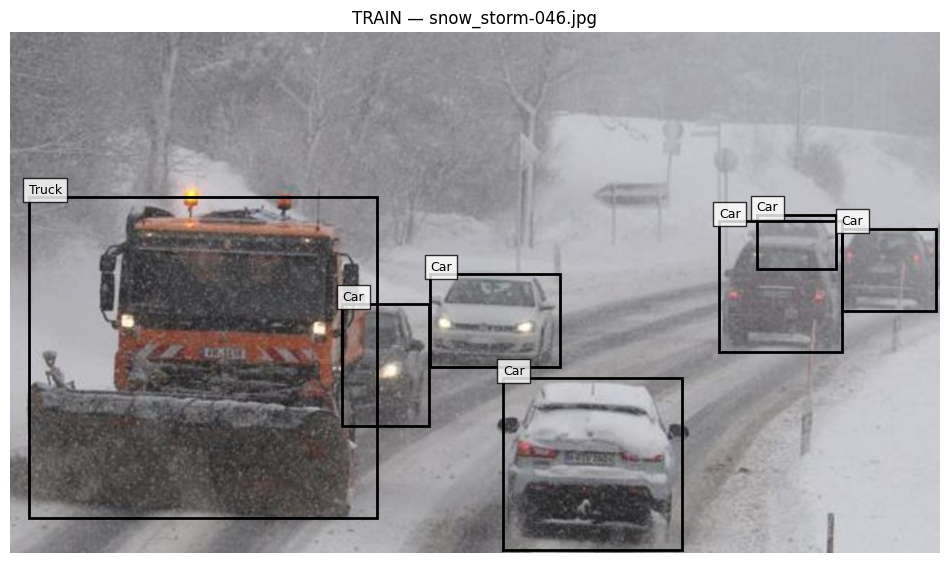

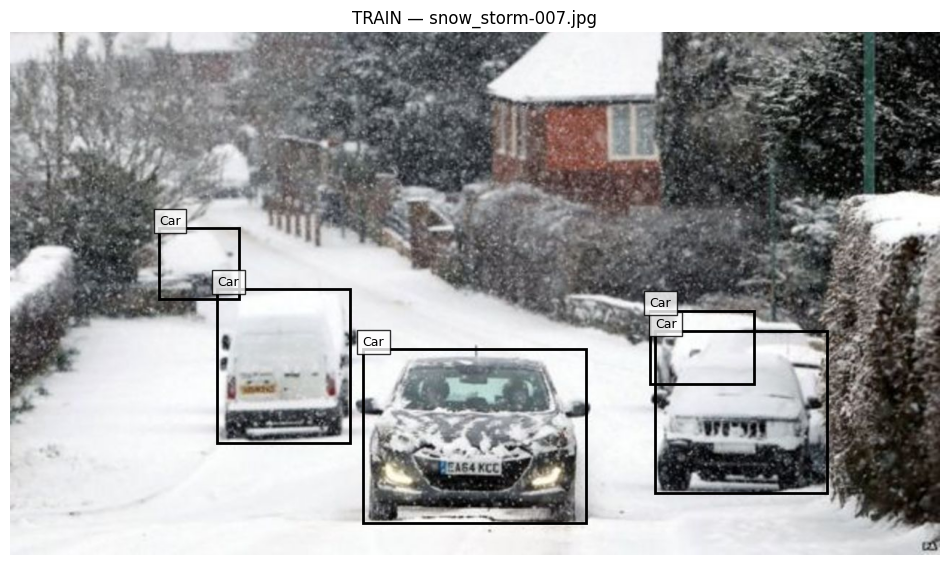

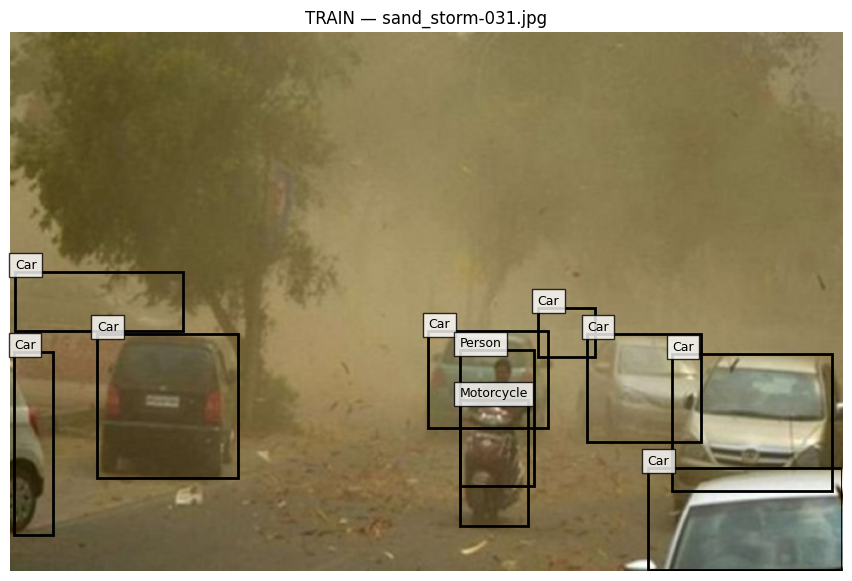

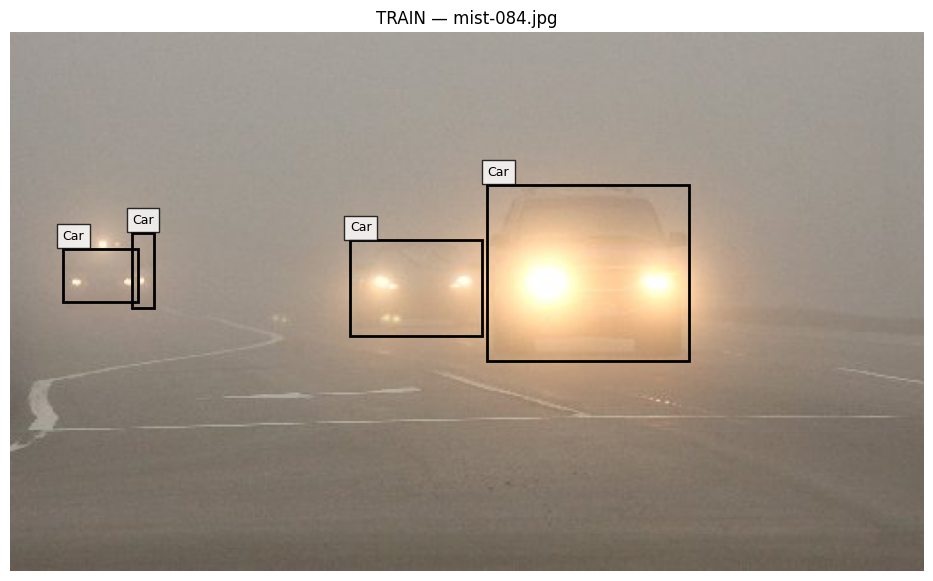

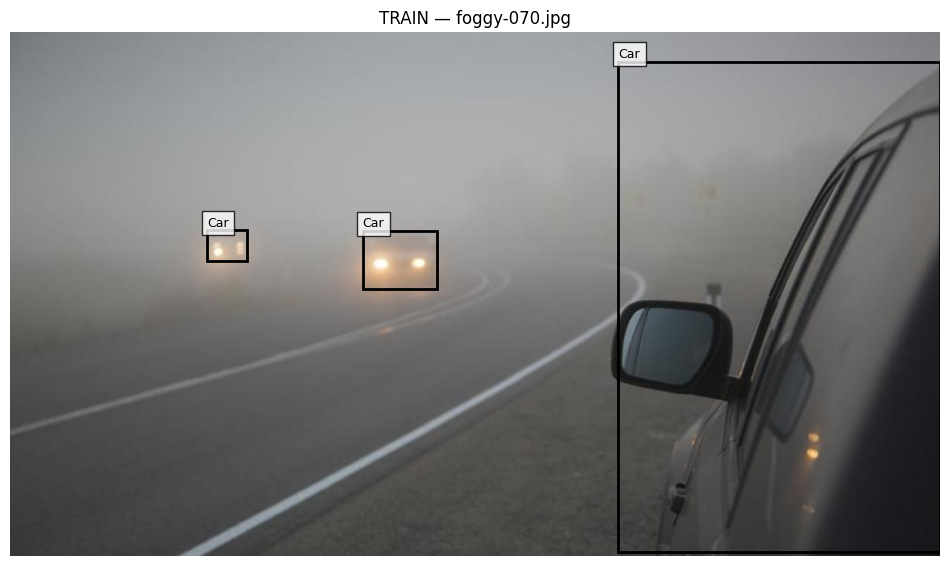

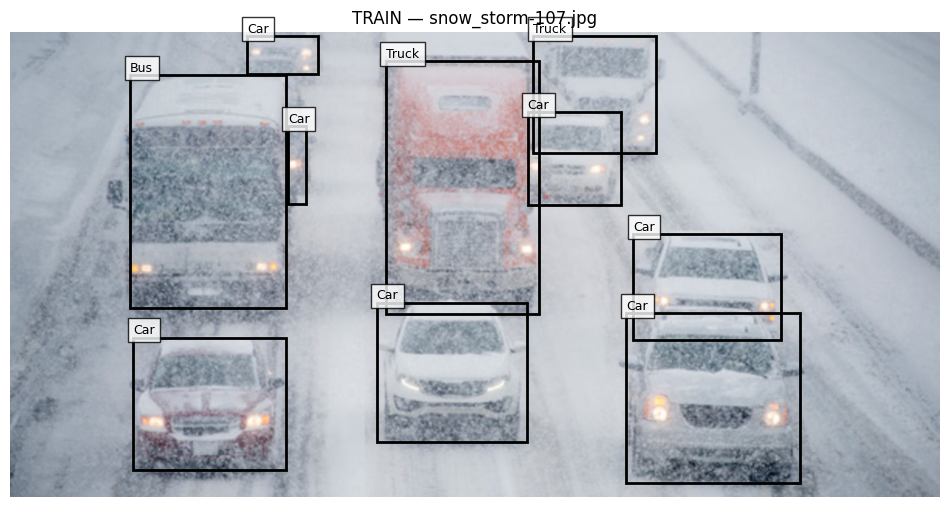

In [ ]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

final_class_names = {
    0: "Person",
    1: "Bicycle",
    2: "Car",
    3: "Motorcycle",
    4: "Bus",
    5: "Truck"
}

random.seed(306)

train_image_dir = yolo_root / "images" / "train"
train_label_dir = yolo_root / "labels" / "train"

train_images_final = [
    p for p in train_image_dir.iterdir()
    if p.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".bmp"
    }
]

samples = random.sample(
    train_images_final,
    6
)

for image_path in samples:

    label_path = (
        train_label_dir /
        f"{image_path.stem}.txt"
    )

    image = Image.open(
        image_path
    ).convert("RGB")

    width, height = image.size

    fig, ax = plt.subplots(
        figsize=(12, 7)
    )

    ax.imshow(image)

    text = label_path.read_text().strip()

    if text:

        for line in text.splitlines():

            class_id, x, y, w, h = map(
                float,
                line.split()
            )

            class_id = int(class_id)

            box_w = w * width
            box_h = h * height

            x_min = (
                x * width -
                box_w / 2
            )

            y_min = (
                y * height -
                box_h / 2
            )

            rect = patches.Rectangle(
                (x_min, y_min),
                box_w,
                box_h,
                linewidth=2,
                fill=False
            )

            ax.add_patch(rect)

            ax.text(
                x_min,
                max(0, y_min - 5),
                final_class_names[class_id],
                fontsize=9,
                bbox=dict(
                    facecolor="white",
                    alpha=0.8
                )
            )

    ax.set_title(
        f"TRAIN — {image_path.name}"
    )

    ax.axis("off")

    plt.show()

## Step 11 — Train YOLOv8n Baseline Model


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path
import shutil

drive_project_root = Path(
    "/content/drive/MyDrive/Road_Object_Detection_Project"
)

drive_runs_dir = drive_project_root / "training_runs"
drive_metadata_dir = drive_project_root / "dataset_metadata"

drive_runs_dir.mkdir(
    parents=True,
    exist_ok=True
)

drive_metadata_dir.mkdir(
    parents=True,
    exist_ok=True
)

print("Project folder:", drive_project_root)
print("Training results:", drive_runs_dir)

Project folder: /content/drive/MyDrive/Road_Object_Detection_Project
Training results: /content/drive/MyDrive/Road_Object_Detection_Project/training_runs


In [ ]:
# Save split metadata

for file in metadata_dir.iterdir():
    shutil.copy2(
        file,
        drive_metadata_dir / file.name
    )

# Save YOLO data.yaml

shutil.copy2(
    yaml_path,
    drive_metadata_dir / "data.yaml"
)

print("Saved files:")

for file in drive_metadata_dir.iterdir():
    print(file.name)

Saved files:
train_split.csv
test_split.csv
val_split.csv
data.yaml


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

CUDA available: True
GPU: Tesla T4


In [ ]:
from ultralytics import YOLO

model_n = YOLO("yolov8n.pt")

print("YOLOv8n loaded successfully.")

YOLOv8n loaded successfully.


In [ ]:
results_n = model_n.train(
    data=str(yaml_path),

    epochs=50,
    imgsz=640,
    batch=16,

    device=0,

    seed=306,
    deterministic=True,

    patience=15,

    pretrained=True,

    save=True,
    plots=True,

    project=str(drive_runs_dir),
    name="YOLOv8n_DAWN",

    exist_ok=True,

    workers=2,

    verbose=True
)

Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dawn_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8n_DAWN, nbs=64, nms=False, o

In [ ]:
from pathlib import Path
import pandas as pd

# Reconnect to the already-saved YOLOv8n training folder
yolov8n_run_dir = Path(
    "/content/drive/MyDrive/Road_Object_Detection_Project/"
    "training_runs/YOLOv8n_DAWN"
)

results_csv_n = yolov8n_run_dir / "results.csv"

print("Run folder exists:", yolov8n_run_dir.exists())
print("results.csv exists:", results_csv_n.exists())

# Load training history
history_n = pd.read_csv(results_csv_n)

print("Completed epochs:", len(history_n))

# Find epoch with highest validation mAP50-95
map_col = "metrics/mAP50-95(B)"

best_row_n = history_n.loc[
    history_n[map_col].idxmax()
]

print("\nBEST YOLOv8n TRAINING EPOCH")
print("=" * 45)

print(
    "Epoch:",
    int(best_row_n["epoch"]) + 1
)

print(
    "Precision:",
    round(
        best_row_n["metrics/precision(B)"],
        4
    )
)

print(
    "Recall:",
    round(
        best_row_n["metrics/recall(B)"],
        4
    )
)

print(
    "mAP50:",
    round(
        best_row_n["metrics/mAP50(B)"],
        4
    )
)

print(
    "mAP50-95:",
    round(
        best_row_n["metrics/mAP50-95(B)"],
        4
    )
)

Run folder exists: True
results.csv exists: True
Completed epochs: 50

BEST YOLOv8n TRAINING EPOCH
Epoch: 41
Precision: 0.6158
Recall: 0.4536
mAP50: 0.5542
mAP50-95: 0.3634


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
!pip -q install ultralytics kagglehub iterative-stratification

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 5.3 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
import pandas as pd

drive_project_root = Path(
    "/content/drive/MyDrive/Road_Object_Detection_Project"
)

drive_runs_dir = drive_project_root / "training_runs"

yolov8n_run_dir = drive_runs_dir / "YOLOv8n_DAWN"

results_csv_n = yolov8n_run_dir / "results.csv"

print("YOLOv8n folder exists:", yolov8n_run_dir.exists())
print("results.csv exists:", results_csv_n.exists())
print(
    "best.pt exists:",
    (yolov8n_run_dir / "weights" / "best.pt").exists()
)

YOLOv8n folder exists: True
results.csv exists: True
best.pt exists: True


In [ ]:
history_n = pd.read_csv(results_csv_n)

best_row_n = history_n.loc[
    history_n["metrics/mAP50-95(B)"].idxmax()
]

print("BEST YOLOv8n TRAINING EPOCH")
print("=" * 45)

print("Epoch:", int(best_row_n["epoch"]) + 1)
print(
    "Precision:",
    round(best_row_n["metrics/precision(B)"], 4)
)
print(
    "Recall:",
    round(best_row_n["metrics/recall(B)"], 4)
)
print(
    "mAP50:",
    round(best_row_n["metrics/mAP50(B)"], 4)
)
print(
    "mAP50-95:",
    round(best_row_n["metrics/mAP50-95(B)"], 4)
)

BEST YOLOv8n TRAINING EPOCH
Epoch: 41
Precision: 0.6158
Recall: 0.4536
mAP50: 0.5542
mAP50-95: 0.3634


## Step 12 — Train YOLOv8s

In [ ]:
from pathlib import Path

yaml_path = Path("/content/dawn_yolo/data.yaml")

drive_project_root = Path(
    "/content/drive/MyDrive/Road_Object_Detection_Project"
)

drive_runs_dir = drive_project_root / "training_runs"

print("data.yaml exists:", yaml_path.exists())
print("Drive project exists:", drive_project_root.exists())
print("Training runs folder exists:", drive_runs_dir.exists())

data.yaml exists: False
Drive project exists: True
Training runs folder exists: True


In [ ]:
# ============================================================
# RESTORE DAWN DATASET AFTER COLAB RUNTIME RESET
# ============================================================

from pathlib import Path
import shutil
import pandas as pd
import yaml
import kagglehub

# ------------------------------------------------------------
# 1. Download original DAWN dataset again
# ------------------------------------------------------------

dataset_path = kagglehub.dataset_download(
    "shuvoalok/dawn-dataset"
)

root = Path(dataset_path)

original_images = root / "images"
original_labels = root / "labels"

print("Original images folder:", original_images.exists())
print("Original labels folder:", original_labels.exists())


# ------------------------------------------------------------
# 2. Recreate cleaned DAWN dataset
# ------------------------------------------------------------

clean_root = Path("/content/dawn_clean")
clean_image_dir = clean_root / "images"
clean_label_dir = clean_root / "labels"

clean_image_dir.mkdir(parents=True, exist_ok=True)
clean_label_dir.mkdir(parents=True, exist_ok=True)

# Raw DAWN -> contiguous YOLO IDs
class_mapping = {
    1: 0,   # Person
    2: 1,   # Bicycle
    3: 2,   # Car
    4: 3,   # Motorcycle
    6: 4,   # Bus
    8: 5    # Truck
}

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp"
}

original_image_files = [
    p for p in original_images.iterdir()
    if p.suffix.lower() in image_extensions
]

kept_boxes = 0
removed_boxes = 0

for image_path in original_image_files:

    # Copy image
    shutil.copy2(
        image_path,
        clean_image_dir / image_path.name
    )

    source_label = (
        original_labels /
        f"{image_path.stem}.txt"
    )

    destination_label = (
        clean_label_dir /
        f"{image_path.stem}.txt"
    )

    clean_lines = []

    if source_label.exists():

        text = source_label.read_text().strip()

        if text:

            for line in text.splitlines():

                parts = line.split()

                if len(parts) != 5:
                    continue

                old_class = int(float(parts[0]))

                if old_class in class_mapping:

                    new_class = class_mapping[old_class]

                    clean_lines.append(
                        " ".join(
                            [str(new_class)] + parts[1:]
                        )
                    )

                    kept_boxes += 1

                else:
                    removed_boxes += 1

    # Also preserves haze-012 as an empty label
    destination_label.write_text(
        "\n".join(clean_lines)
    )

print("\nCLEAN DATASET RESTORED")
print("Images:", len(list(clean_image_dir.iterdir())))
print("Target boxes:", kept_boxes)
print("Unsupported boxes removed:", removed_boxes)


# ------------------------------------------------------------
# 3. Load the PERMANENT optimized seed-306 split
# ------------------------------------------------------------

drive_project_root = Path(
    "/content/drive/MyDrive/Road_Object_Detection_Project"
)

drive_runs_dir = drive_project_root / "training_runs"

drive_metadata_dir = (
    drive_project_root /
    "dataset_metadata"
)

train_df = pd.read_csv(
    drive_metadata_dir /
    "train_split.csv"
)

val_df = pd.read_csv(
    drive_metadata_dir /
    "val_split.csv"
)

test_df = pd.read_csv(
    drive_metadata_dir /
    "test_split.csv"
)

print("\nLOCKED SPLIT LOADED")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


# ------------------------------------------------------------
# 4. Recreate final YOLO structure
# ------------------------------------------------------------

yolo_root = Path("/content/dawn_yolo")

for split in ["train", "val", "test"]:

    (yolo_root / "images" / split).mkdir(
        parents=True,
        exist_ok=True
    )

    (yolo_root / "labels" / split).mkdir(
        parents=True,
        exist_ok=True
    )


def restore_split(df, split_name):

    for image_name in df["image_name"]:

        source_image = (
            clean_image_dir /
            image_name
        )

        source_label = (
            clean_label_dir /
            f"{Path(image_name).stem}.txt"
        )

        shutil.copy2(
            source_image,
            yolo_root /
            "images" /
            split_name /
            image_name
        )

        shutil.copy2(
            source_label,
            yolo_root /
            "labels" /
            split_name /
            source_label.name
        )


restore_split(train_df, "train")
restore_split(val_df, "val")
restore_split(test_df, "test")


# ------------------------------------------------------------
# 5. Recreate data.yaml
# ------------------------------------------------------------

data_yaml = {
    "path": str(yolo_root),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "Person",
        1: "Bicycle",
        2: "Car",
        3: "Motorcycle",
        4: "Bus",
        5: "Truck"
    }
}

yaml_path = yolo_root / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.dump(
        data_yaml,
        f,
        sort_keys=False
    )


# ------------------------------------------------------------
# 6. Final verification
# ------------------------------------------------------------

print("\nFINAL YOLO DATASET")

for split in ["train", "val", "test"]:

    n_images = len(
        list(
            (yolo_root / "images" / split)
            .glob("*")
        )
    )

    n_labels = len(
        list(
            (yolo_root / "labels" / split)
            .glob("*.txt")
        )
    )

    print(
        f"{split}: "
        f"{n_images} images, "
        f"{n_labels} labels"
    )

print("\ndata.yaml exists:", yaml_path.exists())
print("YOLO dataset restored successfully.")

100%|██████████| 132M/132M [00:00<00:00, 142MB/s]

Extracting files...


Original images folder: True
Original labels folder: True

CLEAN DATASET RESTORED
Images: 1027
Target boxes: 7845
Unsupported boxes removed: 1

LOCKED SPLIT LOADED
Train: 718
Validation: 154
Test: 155

FINAL YOLO DATASET
train: 718 images, 718 labels
val: 154 images, 154 labels
test: 155 images, 155 labels

data.yaml exists: True
YOLO dataset restored successfully.


In [ ]:
print("data.yaml exists:", yaml_path.exists())
print("Drive project exists:", drive_project_root.exists())
print("Training runs folder exists:", drive_runs_dir.exists())

data.yaml exists: True
Drive project exists: True
Training runs folder exists: True


In [ ]:
from ultralytics import YOLO

model_s = YOLO("yolov8s.pt")

print("YOLOv8s loaded successfully.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
YOLOv8s loaded successfully.


In [ ]:
results_s = model_s.train(
    data=str(yaml_path),

    epochs=50,
    imgsz=640,
    batch=16,

    device=0,

    seed=306,
    deterministic=True,

    patience=15,

    pretrained=True,

    save=True,
    plots=True,

    project=str(drive_runs_dir),
    name="YOLOv8s_DAWN",

    exist_ok=True,

    workers=2,

    verbose=True
)

Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dawn_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8s_DAWN, nbs=64, nms=False, o

In [ ]:
yolov8s_run_dir = (
    drive_runs_dir /
    "YOLOv8s_DAWN"
)

best_s_path = (
    yolov8s_run_dir /
    "weights" /
    "best.pt"
)

last_s_path = (
    yolov8s_run_dir /
    "weights" /
    "last.pt"
)

print("best.pt exists:", best_s_path.exists())
print("last.pt exists:", last_s_path.exists())

best.pt exists: True
last.pt exists: True


In [ ]:
import pandas as pd

results_csv_s = (
    yolov8s_run_dir /
    "results.csv"
)

history_s = pd.read_csv(results_csv_s)

best_row_s = history_s.loc[
    history_s["metrics/mAP50-95(B)"].idxmax()
]

print("BEST YOLOv8s TRAINING EPOCH")
print("=" * 45)

print("Epoch:", int(best_row_s["epoch"]) + 1)
print(
    "Precision:",
    round(best_row_s["metrics/precision(B)"], 4)
)
print(
    "Recall:",
    round(best_row_s["metrics/recall(B)"], 4)
)
print(
    "mAP50:",
    round(best_row_s["metrics/mAP50(B)"], 4)
)
print(
    "mAP50-95:",
    round(best_row_s["metrics/mAP50-95(B)"], 4)
)
print("Completed epochs:", len(history_s))

BEST YOLOv8s TRAINING EPOCH
Epoch: 51
Precision: 0.7188
Recall: 0.5525
mAP50: 0.6084
mAP50-95: 0.4068
Completed epochs: 50


In [ ]:
import pandas as pd

results_csv_s = yolov8s_run_dir / "results.csv"
history_s = pd.read_csv(results_csv_s)

best_row_s = history_s.loc[
    history_s["metrics/mAP50-95(B)"].idxmax()
]

print("BEST YOLOv8s TRAINING EPOCH")
print("=" * 45)

print("Epoch:", int(best_row_s["epoch"]) + 1)
print("Precision:", round(best_row_s["metrics/precision(B)"], 4))
print("Recall:", round(best_row_s["metrics/recall(B)"], 4))
print("mAP50:", round(best_row_s["metrics/mAP50(B)"], 4))
print("mAP50-95:", round(best_row_s["metrics/mAP50-95(B)"], 4))
print("Completed epochs:", len(history_s))

BEST YOLOv8s TRAINING EPOCH
Epoch: 51
Precision: 0.7188
Recall: 0.5525
mAP50: 0.6084
mAP50-95: 0.4068
Completed epochs: 50


## Step 13 — Train YOLOv8m

In [ ]:
from ultralytics import YOLO

model_m = YOLO("yolov8m.pt")

print("YOLOv8m loaded successfully.")

YOLOv8m loaded successfully.


In [ ]:
from ultralytics import YOLO

model_m = YOLO("yolov8m.pt")

print("YOLOv8m loaded successfully.")

YOLOv8m loaded successfully.


In [ ]:
results_m = model_m.train(
    data=str(yaml_path),

    epochs=50,
    imgsz=640,
    batch=16,

    device=0,

    seed=306,
    deterministic=True,

    patience=15,

    pretrained=True,

    save=True,
    plots=True,

    project=str(drive_runs_dir),
    name="YOLOv8m_DAWN",

    exist_ok=True,

    workers=2,

    verbose=True
)

Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dawn_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/Road_Object_Detection_Project/training_runs/YOLOv8m_DAWN/weights/best.pt,

In [ ]:
yolov8m_run_dir = drive_runs_dir / "YOLOv8m_DAWN"

best_m_path = yolov8m_run_dir / "weights" / "best.pt"
last_m_path = yolov8m_run_dir / "weights" / "last.pt"

print("best.pt exists:", best_m_path.exists())
print("last.pt exists:", last_m_path.exists())

best.pt exists: True
last.pt exists: True


## Step 14 — Final Validation Comparison



In [ ]:
from pathlib import Path
from ultralytics import YOLO
import pandas as pd

# ------------------------------------------------------------
# Model checkpoint paths
# ------------------------------------------------------------

best_n_path = (
    drive_runs_dir /
    "YOLOv8n_DAWN" /
    "weights" /
    "best.pt"
)

best_s_path = (
    drive_runs_dir /
    "YOLOv8s_DAWN" /
    "weights" /
    "best.pt"
)

best_m_path = (
    drive_runs_dir /
    "YOLOv8m_DAWN" /
    "weights" /
    "best.pt"
)

print("YOLOv8n:", best_n_path.exists())
print("YOLOv8s:", best_s_path.exists())
print("YOLOv8m:", best_m_path.exists())

YOLOv8n: True
YOLOv8s: True
YOLOv8m: True


In [ ]:
validation_results = {}

model_paths = {
    "YOLOv8n": best_n_path,
    "YOLOv8s": best_s_path,
    "YOLOv8m": best_m_path
}

for model_name, model_path in model_paths.items():

    print("\n" + "=" * 60)
    print(f"VALIDATING {model_name}")
    print("=" * 60)

    model = YOLO(str(model_path))

    result = model.val(
        data=str(yaml_path),
        split="val",
        imgsz=640,
        batch=16,
        device=0,
        plots=True,

        project=str(drive_runs_dir),
        name=f"{model_name}_FINAL_VAL",

        exist_ok=True
    )

    validation_results[model_name] = result


VALIDATING YOLOv8n
Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2458.4±866.9 MB/s, size: 293.9 KB)
val: Scanning /content/dawn_yolo/labels/val.cache... 154 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 154/154 43.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.2it/s 4.5s
                   all        154       1233      0.644      0.449      0.553      0.362
                Person         31         73      0.752      0.562      0.656      0.408
               Bicycle          3          4          0          0      0.124     0.0568
                   Car        152       1031      0.894      0.787      0.869      0.581
            Motorcycle          7         12        0.8      0.417      0.514      0.307
                   Bus     

In [ ]:
rows = []

for model_name, result in validation_results.items():

    precision = result.box.mp
    recall = result.box.mr

    # F1 from mean precision and mean recall
    if (precision + recall) > 0:
        f1 = (
            2 * precision * recall /
            (precision + recall)
        )
    else:
        f1 = 0

    rows.append({
        "Model": model_name,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "mAP50": result.box.map50,
        "mAP50-95": result.box.map
    })

validation_comparison = pd.DataFrame(rows)

validation_comparison = validation_comparison.sort_values(
    by="mAP50-95",
    ascending=False
).reset_index(drop=True)

print("\nFINAL VALIDATION COMPARISON")
print("=" * 75)

display(
    validation_comparison.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "mAP50": "{:.4f}",
        "mAP50-95": "{:.4f}"
    })
)


FINAL VALIDATION COMPARISON


,Model,Precision,Recall,F1,mAP50,mAP50-95
0,YOLOv8m,0.5749,0.6232,0.5981,0.6036,0.4092
1,YOLOv8s,0.7290,0.5666,0.6377,0.6145,0.4027
2,YOLOv8n,0.6440,0.4493,0.5293,0.5527,0.3625


In [ ]:
comparison_dir = (
    drive_project_root /
    "final_results"
)

comparison_dir.mkdir(
    parents=True,
    exist_ok=True
)

validation_csv = (
    comparison_dir /
    "validation_model_comparison.csv"
)

validation_comparison.to_csv(
    validation_csv,
    index=False
)

print(
    "Saved:",
    validation_csv
)

Saved: /content/drive/MyDrive/Road_Object_Detection_Project/final_results/validation_model_comparison.csv


## Step 15 — Final Evaluation on the Untouched Test Set


In [ ]:
from ultralytics import YOLO
import pandas as pd
import torch
import gc

test_results = {}

for model_name, model_path in model_paths.items():

    print("\n" + "=" * 65)
    print(f"FINAL TEST EVALUATION — {model_name}")
    print("=" * 65)

    model = YOLO(str(model_path))

    result = model.val(
        data=str(yaml_path),
        split="test",

        imgsz=640,
        batch=16,
        device=0,

        plots=True,

        project=str(drive_runs_dir),
        name=f"{model_name}_FINAL_TEST",

        exist_ok=True
    )

    test_results[model_name] = result

    del model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


FINAL TEST EVALUATION — YOLOv8n
Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 26.0±15.3 MB/s, size: 112.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/dawn_yolo/labels/test... 155 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 155/155 421.3it/s 0.4s
val: New cache created: /content/dawn_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 1.7it/s 6.0s
                   all        155       1072      0.828      0.501      0.584      0.355
                Person         32         69      0.837      0.522      0.654      0.361
               Bicycle          3          4          1          0     0.

In [ ]:
test_rows = []

for model_name, result in test_results.items():

    precision = float(result.box.mp)
    recall = float(result.box.mr)

    if precision + recall > 0:
        f1 = (
            2 * precision * recall /
            (precision + recall)
        )
    else:
        f1 = 0.0

    test_rows.append({
        "Model": model_name,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "mAP50": float(result.box.map50),
        "mAP50-95": float(result.box.map)
    })

test_comparison = pd.DataFrame(test_rows)

test_comparison = test_comparison.sort_values(
    by="mAP50-95",
    ascending=False
).reset_index(drop=True)

print("\nFINAL TEST-SET MODEL COMPARISON")
print("=" * 80)

display(
    test_comparison.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "mAP50": "{:.4f}",
        "mAP50-95": "{:.4f}"
    })
)


FINAL TEST-SET MODEL COMPARISON


,Model,Precision,Recall,F1,mAP50,mAP50-95
0,YOLOv8s,0.8728,0.5843,0.7000,0.6927,0.4253
1,YOLOv8m,0.7242,0.6146,0.6649,0.6446,0.4069
2,YOLOv8n,0.8279,0.5009,0.6242,0.5844,0.3552


In [ ]:
test_csv = (
    comparison_dir /
    "final_test_model_comparison.csv"
)

test_comparison.to_csv(
    test_csv,
    index=False
)

print("Saved:", test_csv)

Saved: /content/drive/MyDrive/Road_Object_Detection_Project/final_results/final_test_model_comparison.csv


In [ ]:
class_names = [
    "Person",
    "Bicycle",
    "Car",
    "Motorcycle",
    "Bus",
    "Truck"
]

per_class_rows = []

for model_name, result in test_results.items():

    for class_id, class_name in enumerate(class_names):

        precision = float(result.box.p[class_id])
        recall = float(result.box.r[class_id])

        if precision + recall > 0:
            f1 = (
                2 * precision * recall /
                (precision + recall)
            )
        else:
            f1 = 0.0

        per_class_rows.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "AP50": float(result.box.ap50[class_id]),
            "AP50-95": float(result.box.ap[class_id])
        })

per_class_test = pd.DataFrame(
    per_class_rows
)

display(
    per_class_test.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "AP50": "{:.4f}",
        "AP50-95": "{:.4f}"
    })
)

,Model,Class,Precision,Recall,F1,AP50,AP50-95
0,YOLOv8n,Person,0.8373,0.5217,0.6429,0.6541,0.3614
1,YOLOv8n,Bicycle,1.0000,0.0000,0.0000,0.0448,0.0182
2,YOLOv8n,Car,0.9087,0.7942,0.8476,0.8984,0.5984
3,YOLOv8n,Motorcycle,0.7215,0.6364,0.6763,0.7117,0.3504
4,YOLOv8n,Bus,0.7432,0.5238,0.6145,0.5337,0.4088
5,YOLOv8n,Truck,0.7567,0.5294,0.6230,0.6640,0.3940
6,YOLOv8s,Person,0.9499,0.5491,0.6959,0.7541,0.4655
7,YOLOv8s,Bicycle,1.0000,0.4842,0.6525,0.4950,0.2403
8,YOLOv8s,Car,0.9242,0.8092,0.8629,0.9053,0.6207
9,YOLOv8s,Motorcycle,0.9129,0.5455,0.6829,0.7746,0.4460


In [ ]:
per_class_csv = (
    comparison_dir /
    "final_test_per_class_metrics.csv"
)

per_class_test.to_csv(
    per_class_csv,
    index=False
)

print("Saved:", per_class_csv)

Saved: /content/drive/MyDrive/Road_Object_Detection_Project/final_results/final_test_per_class_metrics.csv


## Step 16 — Weather-Wise Test Evaluation


In [ ]:
from pathlib import Path
import pandas as pd
import shutil
import yaml

# ------------------------------------------------------------
# Load locked test split
# ------------------------------------------------------------

test_split_path = (
    drive_project_root /
    "dataset_metadata" /
    "test_split.csv"
)

test_df = pd.read_csv(test_split_path)

print("Test images:", len(test_df))
print(test_df.head())

Test images: 155
           image_name                                     image_path  \
0  rain_storm-654.jpg  /content/dawn_clean/images/rain_storm-654.jpg   
1       foggy-076.jpg       /content/dawn_clean/images/foggy-076.jpg   
2        haze-045.jpg        /content/dawn_clean/images/haze-045.jpg   
3        haze-136.jpg        /content/dawn_clean/images/haze-136.jpg   
4  rain_storm-700.jpg  /content/dawn_clean/images/rain_storm-700.jpg   

                                      label_path weather  class_0  class_1  \
0  /content/dawn_clean/labels/rain_storm-654.txt    Rain        0        0   
1       /content/dawn_clean/labels/foggy-076.txt     Fog        0        0   
2        /content/dawn_clean/labels/haze-045.txt     Fog        1        1   
3        /content/dawn_clean/labels/haze-136.txt     Fog        0        0   
4  /content/dawn_clean/labels/rain_storm-700.txt    Rain        0        0   

   class_2  class_3  class_4  class_5  weather_Fog  weather_Rain  \
0        1   

In [ ]:
# ------------------------------------------------------------
# Derive weather condition from DAWN filename
# ------------------------------------------------------------

def get_weather(filename):

    name = filename.lower()

    if (
        "haze" in name
        or "foggy" in name
        or "mist" in name
    ):
        return "Fog"

    elif "rain_storm" in name:
        return "Rain"

    elif "snow_storm" in name:
        return "Snow"

    elif (
        "sand_storm" in name
        or "dusttornado" in name
    ):
        return "Sandstorm"

    return "Unknown"


# Find image filename column automatically
if "image_name" in test_df.columns:
    image_col = "image_name"
elif "filename" in test_df.columns:
    image_col = "filename"
else:
    raise ValueError(
        f"Could not find image filename column. Columns: {test_df.columns.tolist()}"
    )

test_df["Weather"] = test_df[image_col].apply(
    get_weather
)

print(test_df["Weather"].value_counts())

print(
    "\nUnknown:",
    (test_df["Weather"] == "Unknown").sum()
)

Weather
Sandstorm    48
Fog          46
Snow         31
Rain         30
Name: count, dtype: int64

Unknown: 0


In [ ]:
weather_root = Path("/content/weather_test")

if weather_root.exists():
    shutil.rmtree(weather_root)

weather_root.mkdir(
    parents=True,
    exist_ok=True
)

source_images = Path(
    "/content/dawn_yolo/images/test"
)

source_labels = Path(
    "/content/dawn_yolo/labels/test"
)

weather_conditions = [
    "Fog",
    "Rain",
    "Snow",
    "Sandstorm"
]

weather_yamls = {}

for weather in weather_conditions:

    subset = test_df[
        test_df["Weather"] == weather
    ]

    subset_root = (
        weather_root /
        weather
    )

    image_dir = (
        subset_root /
        "images" /
        "test"
    )

    label_dir = (
        subset_root /
        "labels" /
        "test"
    )

    image_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    label_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    for image_name in subset[image_col]:

        src_img = (
            source_images /
            image_name
        )

        src_lbl = (
            source_labels /
            f"{Path(image_name).stem}.txt"
        )

        shutil.copy2(
            src_img,
            image_dir / image_name
        )

        shutil.copy2(
            src_lbl,
            label_dir / src_lbl.name
        )

    weather_yaml = {
        "path": str(subset_root),
        "test": "images/test",

        "names": {
            0: "Person",
            1: "Bicycle",
            2: "Car",
            3: "Motorcycle",
            4: "Bus",
            5: "Truck"
        }
    }

    yaml_file = (
        subset_root /
        "data.yaml"
    )

    with open(yaml_file, "w") as f:
        yaml.safe_dump(
            weather_yaml,
            f,
            sort_keys=False
        )

    weather_yamls[weather] = yaml_file

    print(
        f"{weather}: "
        f"{len(subset)} images"
    )

Fog: 46 images
Rain: 30 images
Snow: 31 images
Sandstorm: 48 images


In [ ]:
weather_counts = []

for weather in weather_conditions:

    subset_root = (
        weather_root /
        weather
    )

    image_dir = (
        subset_root /
        "images" /
        "test"
    )

    label_dir = (
        subset_root /
        "labels" /
        "test"
    )

    num_images = len(
        list(image_dir.glob("*"))
    )

    num_boxes = 0

    for label_file in label_dir.glob("*.txt"):

        text = label_file.read_text().strip()

        if text:
            num_boxes += len(
                text.splitlines()
            )

    weather_counts.append({
        "Weather": weather,
        "Images": num_images,
        "Ground Truth Objects": num_boxes
    })

weather_counts_df = pd.DataFrame(
    weather_counts
)

display(weather_counts_df)

,Weather,Images,Ground Truth Objects
0,Fog,46,181
1,Rain,30,234
2,Snow,31,343
3,Sandstorm,48,314


In [ ]:
# FIX WEATHER YAML FILES

weather_yamls = {}

for weather in weather_conditions:

    subset_root = weather_root / weather

    weather_yaml = {
        "path": str(subset_root),

        # Ultralytics requires these keys
        # They are not used because we evaluate split="test"
        "train": "images/test",
        "val": "images/test",

        "test": "images/test",

        "names": {
            0: "Person",
            1: "Bicycle",
            2: "Car",
            3: "Motorcycle",
            4: "Bus",
            5: "Truck"
        }
    }

    yaml_file = subset_root / "data.yaml"

    with open(yaml_file, "w") as f:
        yaml.safe_dump(
            weather_yaml,
            f,
            sort_keys=False
        )

    weather_yamls[weather] = yaml_file

    print(
        weather,
        "YAML fixed:",
        yaml_file
    )

Fog YAML fixed: /content/weather_test/Fog/data.yaml
Rain YAML fixed: /content/weather_test/Rain/data.yaml
Snow YAML fixed: /content/weather_test/Snow/data.yaml
Sandstorm YAML fixed: /content/weather_test/Sandstorm/data.yaml


In [ ]:
for weather, yaml_file in weather_yamls.items():

    print("\n", weather)
    print("-" * 30)

    print(
        Path(yaml_file).read_text()
    )


 Fog
------------------------------
path: /content/weather_test/Fog
train: images/test
val: images/test
test: images/test
names:
  0: Person
  1: Bicycle
  2: Car
  3: Motorcycle
  4: Bus
  5: Truck


 Rain
------------------------------
path: /content/weather_test/Rain
train: images/test
val: images/test
test: images/test
names:
  0: Person
  1: Bicycle
  2: Car
  3: Motorcycle
  4: Bus
  5: Truck


 Snow
------------------------------
path: /content/weather_test/Snow
train: images/test
val: images/test
test: images/test
names:
  0: Person
  1: Bicycle
  2: Car
  3: Motorcycle
  4: Bus
  5: Truck


 Sandstorm
------------------------------
path: /content/weather_test/Sandstorm
train: images/test
val: images/test
test: images/test
names:
  0: Person
  1: Bicycle
  2: Car
  3: Motorcycle
  4: Bus
  5: Truck



In [ ]:
from ultralytics import YOLO
import torch
import gc

weather_results = []

for model_name, model_path in model_paths.items():

    for weather in weather_conditions:

        print("\n" + "=" * 70)
        print(
            f"{model_name} — {weather.upper()}"
        )
        print("=" * 70)

        model = YOLO(
            str(model_path)
        )

        result = model.val(
            data=str(
                weather_yamls[weather]
            ),

            split="test",

            imgsz=640,
            batch=16,
            device=0,

            plots=False,

            project=str(
                drive_runs_dir
            ),

            name=(
                f"{model_name}_"
                f"TEST_{weather}"
            ),

            exist_ok=True
        )

        precision = float(
            result.box.mp
        )

        recall = float(
            result.box.mr
        )

        if precision + recall > 0:
            f1 = (
                2 * precision * recall
                / (precision + recall)
            )
        else:
            f1 = 0.0

        weather_results.append({
            "Model": model_name,
            "Weather": weather,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "mAP50": float(
                result.box.map50
            ),
            "mAP50-95": float(
                result.box.map
            )
        })

        del model
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


YOLOv8n — FOG
Ultralytics 8.4.135 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1691.8±656.0 MB/s, size: 123.5 KB)
val: Scanning /content/weather_test/Fog/labels/test... 46 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 46/46 1.6Kit/s 0.0s
val: New cache created: /content/weather_test/Fog/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 4.5it/s 0.7s
                   all         46        181      0.601      0.609      0.607       0.35
                Person          8         20      0.676       0.65      0.721      0.459
               Bicycle          2          3      0.829      0.333      0.335      0.151
                   Car         45        136       0.74      0.904      0.912      0.665
            Motorcycle          2          4      0.459  

In [ ]:
weather_comparison = pd.DataFrame(weather_results)

display(
    weather_comparison.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "mAP50": "{:.4f}",
        "mAP50-95": "{:.4f}"
    })
)

,Model,Weather,Precision,Recall,F1,mAP50,mAP50-95
0,YOLOv8n,Fog,0.6005,0.6093,0.6049,0.6074,0.3500
1,YOLOv8n,Rain,0.7899,0.5746,0.6653,0.7153,0.4105
2,YOLOv8n,Snow,0.8811,0.6030,0.7160,0.7497,0.5174
3,YOLOv8n,Sandstorm,0.8470,0.5695,0.6811,0.6268,0.4081
4,YOLOv8s,Fog,0.6670,0.5359,0.5943,0.5790,0.3708
5,YOLOv8s,Rain,0.6643,0.6444,0.6542,0.6999,0.4646
6,YOLOv8s,Snow,0.9020,0.6165,0.7324,0.7912,0.5032
7,YOLOv8s,Sandstorm,0.8438,0.7180,0.7758,0.8103,0.5000
8,YOLOv8m,Fog,0.6887,0.5374,0.6037,0.6007,0.3659
9,YOLOv8m,Rain,0.8367,0.5968,0.6967,0.6672,0.4561


In [ ]:
yolov8s_weather = (
    weather_comparison[
        weather_comparison["Model"] == "YOLOv8s"
    ]
    .sort_values(
        "mAP50-95",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    yolov8s_weather.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "mAP50": "{:.4f}",
        "mAP50-95": "{:.4f}"
    })
)

,Model,Weather,Precision,Recall,F1,mAP50,mAP50-95
0,YOLOv8s,Snow,0.9020,0.6165,0.7324,0.7912,0.5032
1,YOLOv8s,Sandstorm,0.8438,0.7180,0.7758,0.8103,0.5000
2,YOLOv8s,Rain,0.6643,0.6444,0.6542,0.6999,0.4646
3,YOLOv8s,Fog,0.6670,0.5359,0.5943,0.5790,0.3708


In [ ]:
weather_csv = (
    comparison_dir /
    "weather_wise_test_metrics.csv"
)

weather_comparison.to_csv(
    weather_csv,
    index=False
)

weather_counts_csv = (
    comparison_dir /
    "weather_test_distribution.csv"
)

weather_counts_df.to_csv(
    weather_counts_csv,
    index=False
)

print("Saved:", weather_csv)
print("Saved:", weather_counts_csv)

Saved: /content/drive/MyDrive/Road_Object_Detection_Project/final_results/weather_wise_test_metrics.csv
Saved: /content/drive/MyDrive/Road_Object_Detection_Project/final_results/weather_test_distribution.csv


## Step 17 — Final Visual Evaluation

In [ ]:
from pathlib import Path
import shutil

visual_dir = (
    drive_project_root /
    "final_results" /
    "visual_evaluation"
)

visual_dir.mkdir(
    parents=True,
    exist_ok=True
)

yolov8s_test_run = (
    drive_runs_dir /
    "YOLOv8s_FINAL_TEST"
)

print("YOLOv8s final test folder exists:",
      yolov8s_test_run.exists())

print("Visual output folder:",
      visual_dir)

YOLOv8s final test folder exists: True
Visual output folder: /content/drive/MyDrive/Road_Object_Detection_Project/final_results/visual_evaluation


In [ ]:
plot_files = sorted(
    yolov8s_test_run.glob("*.png")
)

print("Available YOLOv8s test plots:\n")

for file in plot_files:
    print(file.name)

Available YOLOv8s test plots:

BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png


In [ ]:
important_plots = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png"
]

copied_plots = []

for filename in important_plots:

    src = yolov8s_test_run / filename

    if src.exists():

        dst = visual_dir / filename

        shutil.copy2(
            src,
            dst
        )

        copied_plots.append(dst)

        print("Copied:", filename)

    else:
        print("Not found:", filename)

Copied: confusion_matrix.png
Copied: confusion_matrix_normalized.png
Copied: BoxPR_curve.png
Copied: BoxF1_curve.png
Copied: BoxP_curve.png
Copied: BoxR_curve.png


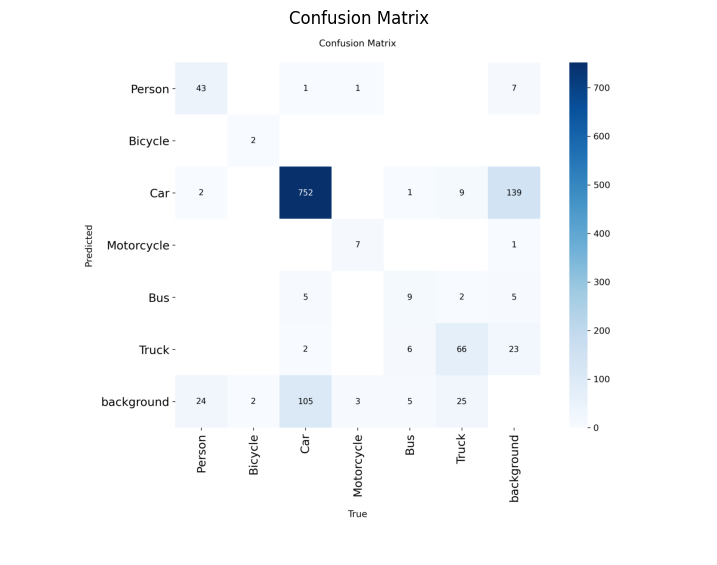

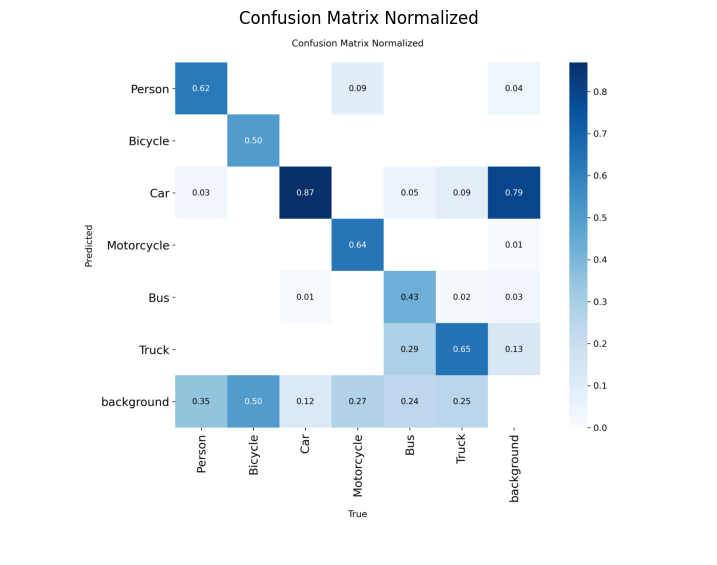

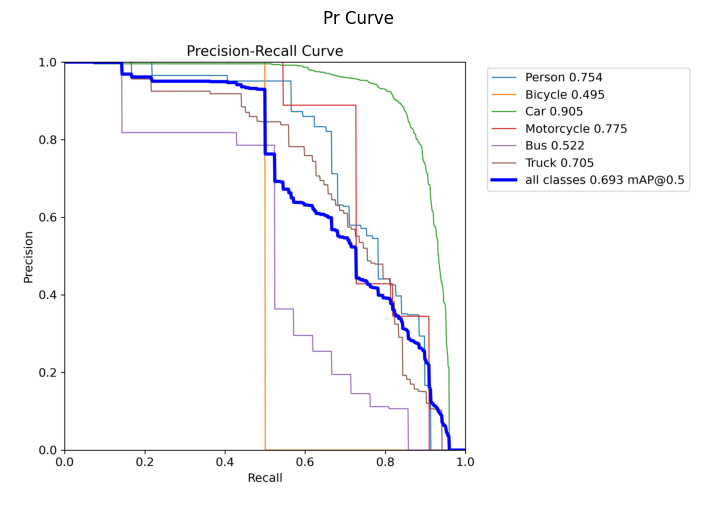

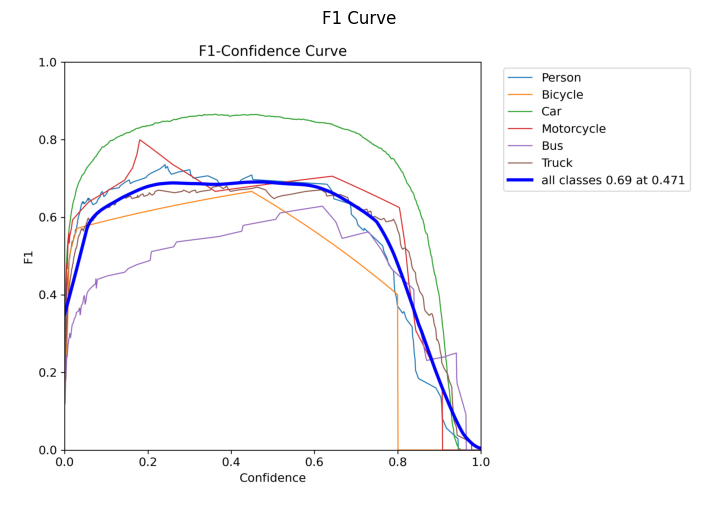

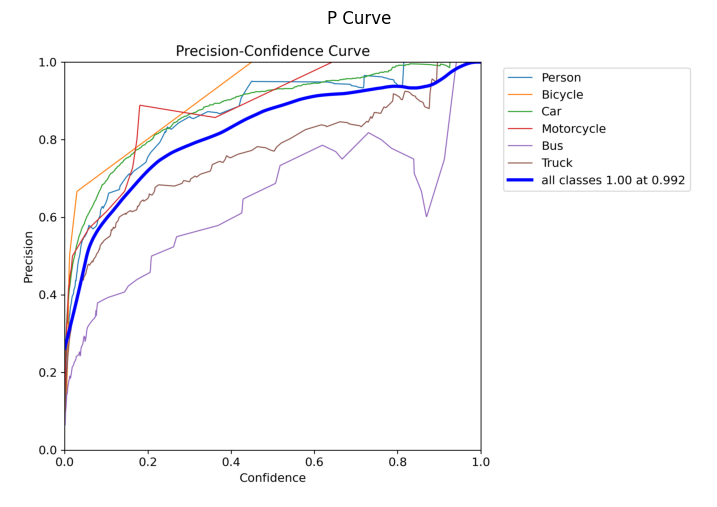

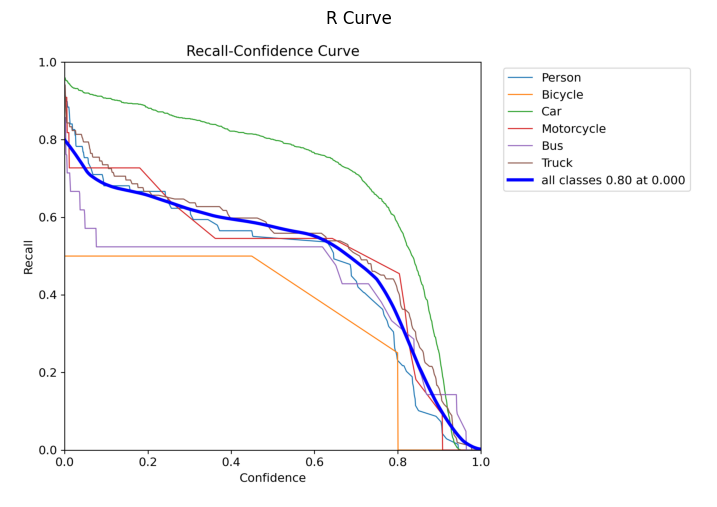

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

for plot_path in copied_plots:

    img = Image.open(plot_path)

    plt.figure(figsize=(9, 7))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        plot_path.stem
        .replace("Box", "")
        .replace("_", " ")
        .title()
    )
    plt.show()

In [ ]:
from ultralytics import YOLO
from pathlib import Path

best_model_s = YOLO(str(best_s_path))

test_image_dir = Path(
    "/content/dawn_yolo/images/test"
)

test_images = sorted([
    p for p in test_image_dir.iterdir()
    if p.suffix.lower()
    in [".jpg", ".jpeg", ".png", ".bmp"]
])

print("Test images:", len(test_images))

qualitative_predictions = best_model_s.predict(
    source=[str(p) for p in test_images],
    imgsz=640,
    conf=0.25,
    device=0,
    save=False,
    verbose=False
)

print(
    "Prediction results:",
    len(qualitative_predictions)
)

Test images: 155
Prediction results: 155


In [ ]:
import numpy as np

def load_ground_truth(
    label_path,
    image_width,
    image_height
):

    boxes = []
    classes = []

    if not label_path.exists():
        return (
            np.empty((0, 4)),
            np.empty((0,), dtype=int)
        )

    text = label_path.read_text().strip()

    if not text:
        return (
            np.empty((0, 4)),
            np.empty((0,), dtype=int)
        )

    for line in text.splitlines():

        parts = line.split()

        cls = int(parts[0])

        x = float(parts[1])
        y = float(parts[2])
        w = float(parts[3])
        h = float(parts[4])

        x1 = (x - w / 2) * image_width
        y1 = (y - h / 2) * image_height
        x2 = (x + w / 2) * image_width
        y2 = (y + h / 2) * image_height

        boxes.append([x1, y1, x2, y2])
        classes.append(cls)

    return (
        np.array(boxes),
        np.array(classes)
    )


def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = (
        max(0, x2 - x1)
        * max(0, y2 - y1)
    )

    area1 = (
        max(0, box1[2] - box1[0])
        * max(0, box1[3] - box1[1])
    )

    area2 = (
        max(0, box2[2] - box2[0])
        * max(0, box2[3] - box2[1])
    )

    union = area1 + area2 - intersection

    if union <= 0:
        return 0.0

    return intersection / union

In [ ]:
import pandas as pd

qualitative_rows = []

label_dir = Path(
    "/content/dawn_yolo/labels/test"
)

for pred_result in qualitative_predictions:

    image_path = Path(pred_result.path)

    height, width = pred_result.orig_shape

    label_path = (
        label_dir /
        f"{image_path.stem}.txt"
    )

    gt_boxes, gt_classes = load_ground_truth(
        label_path,
        width,
        height
    )

    if pred_result.boxes is not None:

        pred_boxes = (
            pred_result.boxes.xyxy
            .cpu()
            .numpy()
        )

        pred_classes = (
            pred_result.boxes.cls
            .cpu()
            .numpy()
            .astype(int)
        )

    else:

        pred_boxes = np.empty((0, 4))

        pred_classes = np.empty(
            (0,),
            dtype=int
        )

    matched_predictions = set()

    tp = 0

    for gt_index, gt_box in enumerate(gt_boxes):

        gt_class = gt_classes[gt_index]

        best_iou = 0
        best_pred_index = None

        for pred_index, pred_box in enumerate(
            pred_boxes
        ):

            if pred_index in matched_predictions:
                continue

            if pred_classes[pred_index] != gt_class:
                continue

            iou = calculate_iou(
                gt_box,
                pred_box
            )

            if iou > best_iou:

                best_iou = iou
                best_pred_index = pred_index

        if (
            best_pred_index is not None
            and best_iou >= 0.50
        ):

            tp += 1

            matched_predictions.add(
                best_pred_index
            )

    fp = (
        len(pred_boxes)
        - len(matched_predictions)
    )

    fn = len(gt_boxes) - tp

    if (2 * tp + fp + fn) > 0:

        image_f1 = (
            2 * tp /
            (2 * tp + fp + fn)
        )

    else:
        image_f1 = 1.0

    qualitative_rows.append({
        "Image": image_path.name,
        "Ground Truth Objects": len(gt_boxes),
        "Predicted Objects": len(pred_boxes),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Image_F1": image_f1
    })

qualitative_df = pd.DataFrame(
    qualitative_rows
)

display(qualitative_df.head())

print(
    "\nImages analyzed:",
    len(qualitative_df)
)

,Image,Ground Truth Objects,Predicted Objects,TP,FP,FN,Image_F1
0,dusttornado-003.jpg,23,20,18,2,5,0.837209
1,dusttornado-022.jpg,1,1,1,0,0,1.000000
2,dusttornado-029.jpg,1,1,1,0,0,1.000000
3,dusttornado-032.jpg,2,2,1,1,1,0.500000
4,dusttornado-034.jpg,5,5,4,1,1,0.800000



Images analyzed: 155


In [ ]:
candidate_df = qualitative_df[
    qualitative_df[
        "Ground Truth Objects"
    ] >= 2
].copy()

best_examples = (
    candidate_df
    .sort_values(
        [
            "Image_F1",
            "Ground Truth Objects"
        ],
        ascending=[
            False,
            False
        ]
    )
    .head(4)
)

difficult_examples = (
    candidate_df
    .sort_values(
        [
            "Image_F1",
            "FN",
            "FP"
        ],
        ascending=[
            True,
            False,
            False
        ]
    )
    .head(4)
)

print("GOOD DETECTION EXAMPLES")
display(best_examples)

print("\nDIFFICULT / FAILURE EXAMPLES")
display(difficult_examples)

GOOD DETECTION EXAMPLES


,Image,Ground Truth Objects,Predicted Objects,TP,FP,FN,Image_F1
8,foggy-048.jpg,8,8,8,0,0,1.0
117,sand_storm-935.jpg,8,8,8,0,0,1.0
24,haze-037.jpg,6,6,6,0,0,1.0
55,rain_storm-110.jpg,6,6,6,0,0,1.0



DIFFICULT / FAILURE EXAMPLES


,Image,Ground Truth Objects,Predicted Objects,TP,FP,FN,Image_F1
37,haze-124.jpg,2,0,0,0,2,0.000000
20,haze-013.jpg,9,3,2,1,7,0.333333
28,haze-068.jpg,6,4,2,2,4,0.400000
47,mist-115.jpg,3,2,1,1,2,0.400000


In [ ]:
qualitative_csv = (
    visual_dir /
    "qualitative_image_analysis.csv"
)

qualitative_df.to_csv(
    qualitative_csv,
    index=False
)

print(
    "Saved:",
    qualitative_csv
)

Saved: /content/drive/MyDrive/Road_Object_Detection_Project/final_results/visual_evaluation/qualitative_image_analysis.csv


In [ ]:
import cv2

class_names = [
    "Person",
    "Bicycle",
    "Car",
    "Motorcycle",
    "Bus",
    "Truck"
]


def draw_ground_truth(image, label_path):

    image = image.copy()

    height, width = image.shape[:2]

    gt_boxes, gt_classes = load_ground_truth(
        label_path,
        width,
        height
    )

    for box, cls in zip(
        gt_boxes,
        gt_classes
    ):

        x1, y1, x2, y2 = box.astype(int)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        label = f"GT: {class_names[cls]}"

        cv2.putText(
            image,
            label,
            (x1, max(20, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            2
        )

    return image

In [ ]:
good_dir = visual_dir / "good_examples"
difficult_dir = visual_dir / "difficult_examples"

good_dir.mkdir(
    parents=True,
    exist_ok=True
)

difficult_dir.mkdir(
    parents=True,
    exist_ok=True
)


prediction_lookup = {
    Path(result.path).name: result
    for result in qualitative_predictions
}


def save_comparison_examples(
    dataframe,
    output_dir,
    prefix
):

    for _, row in dataframe.iterrows():

        image_name = row["Image"]

        image_path = (
            test_image_dir /
            image_name
        )

        label_path = (
            label_dir /
            f"{Path(image_name).stem}.txt"
        )

        original = cv2.imread(
            str(image_path)
        )

        gt_image = draw_ground_truth(
            original,
            label_path
        )

        pred_result = prediction_lookup[
            image_name
        ]

        prediction_image = (
            pred_result.plot()
        )

        # Heading on GT image
        cv2.putText(
            gt_image,
            "GROUND TRUTH",
            (20, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (0, 255, 0),
            2
        )

        # Heading on prediction image
        cv2.putText(
            prediction_image,
            "YOLOv8s PREDICTION",
            (20, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (255, 255, 255),
            2
        )

        # Make sizes equal if necessary
        if (
            gt_image.shape
            != prediction_image.shape
        ):

            prediction_image = cv2.resize(
                prediction_image,
                (
                    gt_image.shape[1],
                    gt_image.shape[0]
                )
            )

        comparison = np.hstack([
            gt_image,
            prediction_image
        ])

        output_path = (
            output_dir /
            f"{prefix}_{image_name}"
        )

        cv2.imwrite(
            str(output_path),
            comparison
        )

        print(
            "Saved:",
            output_path.name
        )


save_comparison_examples(
    best_examples,
    good_dir,
    "good"
)

save_comparison_examples(
    difficult_examples,
    difficult_dir,
    "difficult"
)

Saved: good_foggy-048.jpg
Saved: good_sand_storm-935.jpg
Saved: good_haze-037.jpg
Saved: good_rain_storm-110.jpg
Saved: difficult_haze-124.jpg
Saved: difficult_haze-013.jpg
Saved: difficult_haze-068.jpg
Saved: difficult_mist-115.jpg


GOOD DETECTION EXAMPLES


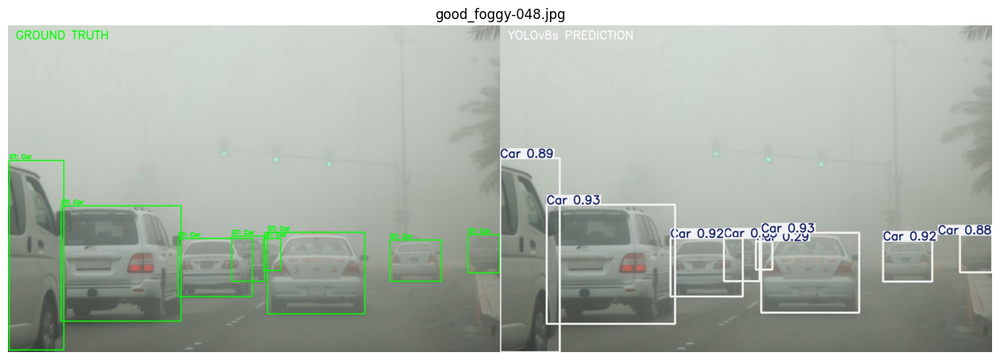

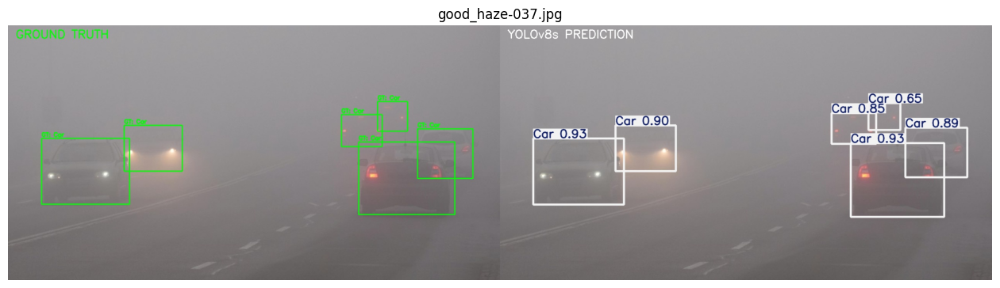

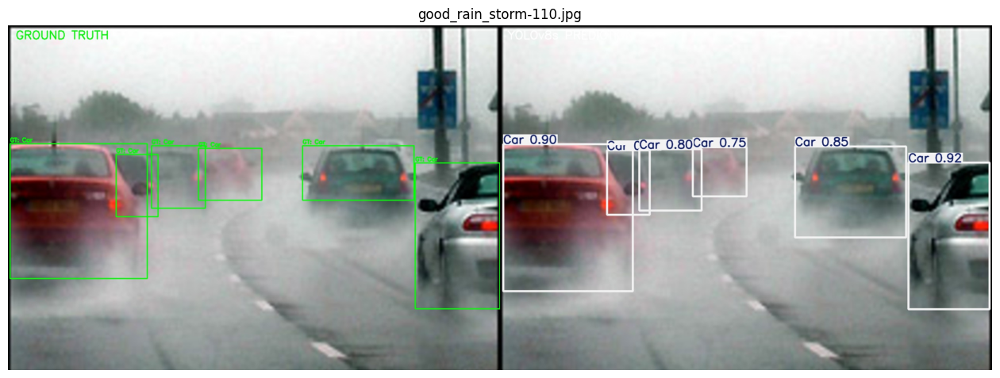

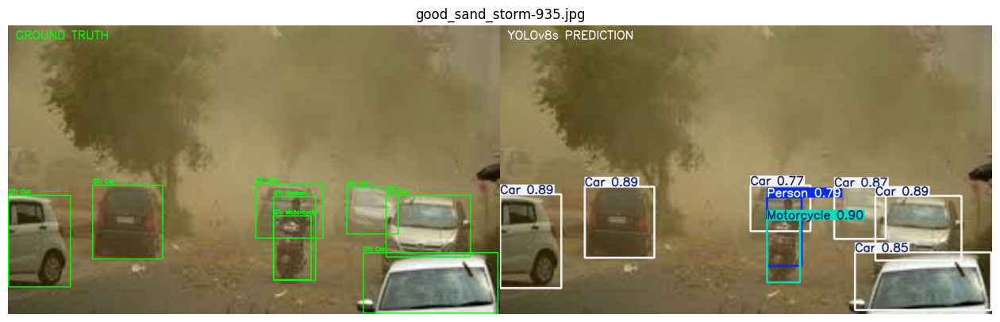


DIFFICULT / FAILURE EXAMPLES


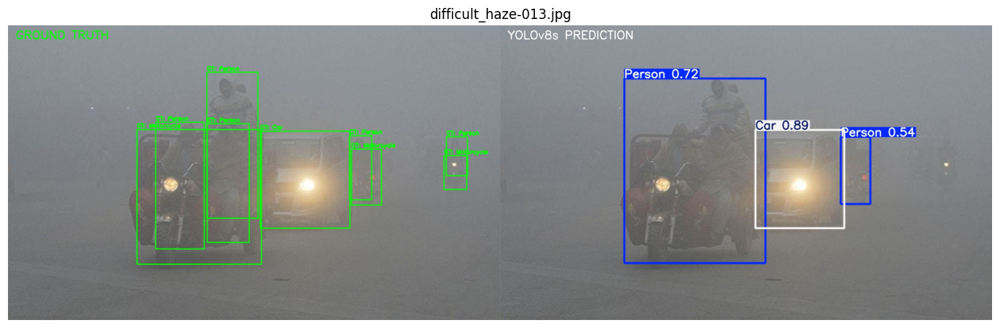

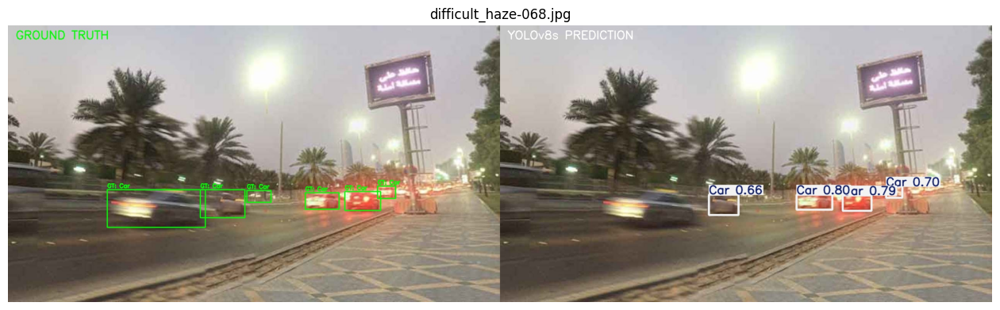

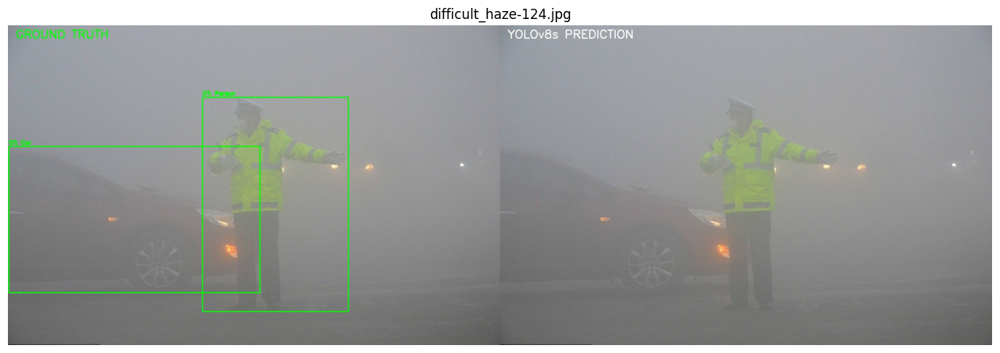

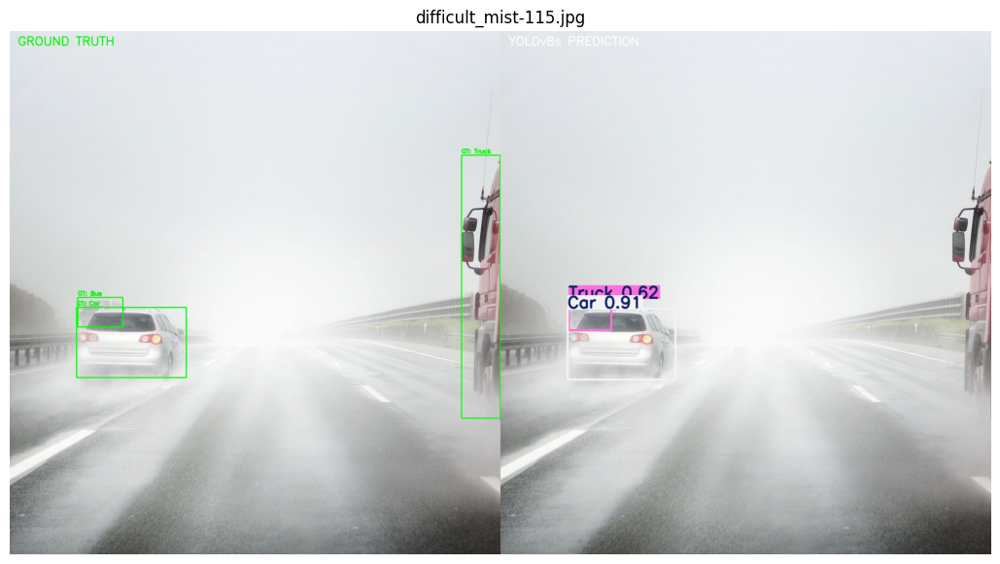

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

print("GOOD DETECTION EXAMPLES")

for image_path in sorted(
    good_dir.glob("*")
):

    img = Image.open(image_path)

    plt.figure(figsize=(16, 7))
    plt.imshow(img)
    plt.axis("off")
    plt.title(image_path.name)
    plt.show()


print("\nDIFFICULT / FAILURE EXAMPLES")

for image_path in sorted(
    difficult_dir.glob("*")
):

    img = Image.open(image_path)

    plt.figure(figsize=(16, 7))
    plt.imshow(img)
    plt.axis("off")
    plt.title(image_path.name)
    plt.show()

In [ ]:
print("STEP 17 — FINAL CHECK")
print("=" * 50)

print(
    "Evaluation plots:",
    len(copied_plots)
)

print(
    "Good examples:",
    len(list(good_dir.glob("*")))
)

print(
    "Difficult examples:",
    len(list(difficult_dir.glob("*")))
)

print(
    "Qualitative CSV exists:",
    qualitative_csv.exists()
)

STEP 17 — FINAL CHECK
Evaluation plots: 6
Good examples: 4
Difficult examples: 4
Qualitative CSV exists: True


## Step 18 — Error Analysis and Final Model Selection


In [ ]:
from pathlib import Path
import pandas as pd

comparison_dir = (
    Path("/content/drive/MyDrive/")
    / "Road_Object_Detection_Project"
    / "final_results"
)

visual_dir = (
    comparison_dir
    / "visual_evaluation"
)

test_comparison = pd.read_csv(
    comparison_dir
    / "final_test_model_comparison.csv"
)

per_class_test = pd.read_csv(
    comparison_dir
    / "final_test_per_class_metrics.csv"
)

weather_comparison = pd.read_csv(
    comparison_dir
    / "weather_wise_test_metrics.csv"
)

qualitative_df = pd.read_csv(
    visual_dir
    / "qualitative_image_analysis.csv"
)

print("All final result files loaded.")

All final result files loaded.


In [ ]:
model_ranking = (
    test_comparison
    .sort_values(
        "mAP50-95",
        ascending=False
    )
    .reset_index(drop=True)
)

print("FINAL MODEL RANKING")

display(
    model_ranking.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "mAP50": "{:.4f}",
        "mAP50-95": "{:.4f}"
    })
)

FINAL MODEL RANKING


,Model,Precision,Recall,F1,mAP50,mAP50-95
0,YOLOv8s,0.8728,0.5843,0.7000,0.6927,0.4253
1,YOLOv8m,0.7242,0.6146,0.6649,0.6446,0.4069
2,YOLOv8n,0.8279,0.5009,0.6242,0.5844,0.3552


In [ ]:
best_model_row = model_ranking.iloc[0]

final_model_name = best_model_row["Model"]

print("SELECTED FINAL MODEL")
print("=" * 50)

print("Model:", final_model_name)
print(
    "Precision:",
    round(best_model_row["Precision"], 4)
)
print(
    "Recall:",
    round(best_model_row["Recall"], 4)
)
print(
    "F1:",
    round(best_model_row["F1"], 4)
)
print(
    "mAP50:",
    round(best_model_row["mAP50"], 4)
)
print(
    "mAP50-95:",
    round(best_model_row["mAP50-95"], 4)
)

SELECTED FINAL MODEL
Model: YOLOv8s
Precision: 0.8728
Recall: 0.5843
F1: 0.7
mAP50: 0.6927
mAP50-95: 0.4253


In [ ]:
baseline = (
    test_comparison[
        test_comparison["Model"]
        == "YOLOv8n"
    ]
    .iloc[0]
)

best = (
    test_comparison[
        test_comparison["Model"]
        == final_model_name
    ]
    .iloc[0]
)

improvement = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1",
        "mAP50",
        "mAP50-95"
    ],

    "YOLOv8n": [
        baseline["Precision"],
        baseline["Recall"],
        baseline["F1"],
        baseline["mAP50"],
        baseline["mAP50-95"]
    ],

    final_model_name: [
        best["Precision"],
        best["Recall"],
        best["F1"],
        best["mAP50"],
        best["mAP50-95"]
    ]
})

improvement["Absolute Improvement"] = (
    improvement[final_model_name]
    - improvement["YOLOv8n"]
)

display(
    improvement.style.format({
        "YOLOv8n": "{:.4f}",
        final_model_name: "{:.4f}",
        "Absolute Improvement": "{:+.4f}"
    })
)

,Metric,YOLOv8n,YOLOv8s,Absolute Improvement
0,Precision,0.8279,0.8728,+0.0449
1,Recall,0.5009,0.5843,+0.0834
2,F1,0.6242,0.7000,+0.0758
3,mAP50,0.5844,0.6927,+0.1083
4,mAP50-95,0.3552,0.4253,+0.0700


In [ ]:
best_class_results = (
    per_class_test[
        per_class_test["Model"]
        == final_model_name
    ]
    .sort_values(
        "AP50-95",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    f"{final_model_name} — "
    "CLASS PERFORMANCE"
)

display(
    best_class_results.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "AP50": "{:.4f}",
        "AP50-95": "{:.4f}"
    })
)

print(
    "\nStrongest class:",
    best_class_results.iloc[0]["Class"]
)

print(
    "Weakest class:",
    best_class_results.iloc[-1]["Class"]
)

YOLOv8s — CLASS PERFORMANCE


,Model,Class,Precision,Recall,F1,AP50,AP50-95
0,YOLOv8s,Car,0.9242,0.8092,0.8629,0.9053,0.6207
1,YOLOv8s,Person,0.9499,0.5491,0.6959,0.7541,0.4655
2,YOLOv8s,Motorcycle,0.9129,0.5455,0.6829,0.7746,0.4460
3,YOLOv8s,Truck,0.7808,0.5938,0.6746,0.7052,0.4265
4,YOLOv8s,Bus,0.6692,0.5238,0.5877,0.5222,0.3525
5,YOLOv8s,Bicycle,1.0000,0.4842,0.6525,0.4950,0.2403



Strongest class: Car
Weakest class: Bicycle


In [ ]:
best_weather_results = (
    weather_comparison[
        weather_comparison["Model"]
        == final_model_name
    ]
    .sort_values(
        "mAP50-95",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    f"{final_model_name} — "
    "WEATHER PERFORMANCE"
)

display(
    best_weather_results.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "mAP50": "{:.4f}",
        "mAP50-95": "{:.4f}"
    })
)

best_weather = (
    best_weather_results.iloc[0]["Weather"]
)

hardest_weather = (
    best_weather_results.iloc[-1]["Weather"]
)

print(
    "\nBest observed weather condition:",
    best_weather
)

print(
    "Hardest observed weather condition:",
    hardest_weather
)

YOLOv8s — WEATHER PERFORMANCE


,Model,Weather,Precision,Recall,F1,mAP50,mAP50-95
0,YOLOv8s,Snow,0.9020,0.6165,0.7324,0.7912,0.5032
1,YOLOv8s,Sandstorm,0.8438,0.7180,0.7758,0.8103,0.5000
2,YOLOv8s,Rain,0.6643,0.6444,0.6542,0.6999,0.4646
3,YOLOv8s,Fog,0.6670,0.5359,0.5943,0.5790,0.3708



Best observed weather condition: Snow
Hardest observed weather condition: Fog


In [ ]:
error_summary = pd.DataFrame({
    "Measure": [
        "Images analyzed",
        "True Positives",
        "False Positives",
        "False Negatives",
        "Mean image-level F1"
    ],

    "Value": [
        len(qualitative_df),
        qualitative_df["TP"].sum(),
        qualitative_df["FP"].sum(),
        qualitative_df["FN"].sum(),
        qualitative_df["Image_F1"].mean()
    ]
})

display(error_summary)

,Measure,Value
0,Images analyzed,155.000000
1,True Positives,879.000000
2,False Positives,214.000000
3,False Negatives,193.000000
4,Mean image-level F1,0.833863


In [ ]:
hardest_images = (
    qualitative_df
    .sort_values(
        [
            "Image_F1",
            "FN",
            "FP"
        ],
        ascending=[
            True,
            False,
            False
        ]
    )
    .head(10)
)

print("10 HARDEST TEST IMAGES")

display(
    hardest_images.style.format({
        "Image_F1": "{:.4f}"
    })
)

10 HARDEST TEST IMAGES


,Image,Ground Truth Objects,Predicted Objects,TP,FP,FN,Image_F1
37,haze-124.jpg,2,0,0,0,2,0.0000
68,rain_storm-614.jpg,1,1,0,1,1,0.0000
20,haze-013.jpg,9,3,2,1,7,0.3333
32,haze-104.jpg,1,5,1,4,0,0.3333
28,haze-068.jpg,6,4,2,2,4,0.4000
47,mist-115.jpg,3,2,1,1,2,0.4000
76,rain_storm-811.jpg,2,3,1,2,1,0.4000
123,sand_storm_g2_-071.jpg,6,3,2,1,4,0.4444
124,snow_storm-001.jpg,8,5,3,2,5,0.4615
127,snow_storm-017.jpg,16,13,7,6,9,0.4828


In [ ]:
def infer_weather(filename):

    name = filename.lower()

    if (
        "haze" in name
        or "foggy" in name
        or "mist" in name
    ):
        return "Fog"

    if "rain_storm" in name:
        return "Rain"

    if "snow_storm" in name:
        return "Snow"

    if (
        "sand_storm" in name
        or "dusttornado" in name
    ):
        return "Sandstorm"

    return "Unknown"


qualitative_df["Weather"] = (
    qualitative_df["Image"]
    .apply(infer_weather)
)

failure_weather = (
    qualitative_df
    .groupby("Weather")
    .agg(
        Images=("Image", "count"),
        Mean_Image_F1=("Image_F1", "mean"),
        False_Positives=("FP", "sum"),
        False_Negatives=("FN", "sum")
    )
    .reset_index()
    .sort_values(
        "Mean_Image_F1"
    )
)

display(
    failure_weather.style.format({
        "Mean_Image_F1": "{:.4f}"
    })
)

,Weather,Images,Mean_Image_F1,False_Positives,False_Negatives
1,Rain,30,0.8167,63,26
0,Fog,46,0.8210,27,41
3,Snow,31,0.8409,65,74
2,Sandstorm,48,0.8524,59,52


In [ ]:
final_selection_summary = pd.DataFrame({
    "Category": [
        "Selected model",
        "Selection criterion",
        "Test Precision",
        "Test Recall",
        "Test F1",
        "Test mAP50",
        "Test mAP50-95",
        "Strongest class",
        "Weakest class",
        "Best observed weather",
        "Hardest observed weather"
    ],

    "Result": [
        final_model_name,
        "Highest overall test mAP50-95",
        f"{best['Precision']:.4f}",
        f"{best['Recall']:.4f}",
        f"{best['F1']:.4f}",
        f"{best['mAP50']:.4f}",
        f"{best['mAP50-95']:.4f}",
        best_class_results.iloc[0]["Class"],
        best_class_results.iloc[-1]["Class"],
        best_weather,
        hardest_weather
    ]
})

display(final_selection_summary)

,Category,Result
0,Selected model,YOLOv8s
1,Selection criterion,Highest overall test mAP50-95
2,Test Precision,0.8728
3,Test Recall,0.5843
4,Test F1,0.7000
5,Test mAP50,0.6927
6,Test mAP50-95,0.4253
7,Strongest class,Car
8,Weakest class,Bicycle
9,Best observed weather,Snow


In [ ]:
error_analysis_dir = (
    comparison_dir
    / "error_analysis"
)

error_analysis_dir.mkdir(
    parents=True,
    exist_ok=True
)

model_ranking.to_csv(
    error_analysis_dir
    / "final_model_ranking.csv",
    index=False
)

improvement.to_csv(
    error_analysis_dir
    / "baseline_improvement.csv",
    index=False
)

failure_weather.to_csv(
    error_analysis_dir
    / "qualitative_weather_errors.csv",
    index=False
)

hardest_images.to_csv(
    error_analysis_dir
    / "hardest_test_images.csv",
    index=False
)

final_selection_summary.to_csv(
    error_analysis_dir
    / "final_model_selection_summary.csv",
    index=False
)

print(
    "Step 18 results saved to:"
)

print(error_analysis_dir)

Step 18 results saved to:
/content/drive/MyDrive/Road_Object_Detection_Project/final_results/error_analysis


In [ ]:
print(
    "STEP 18 COMPLETE"
)

print("=" * 50)

print(
    "Final selected model:",
    final_model_name
)

print(
    "Weakest class:",
    best_class_results.iloc[-1]["Class"]
)

print(
    "Hardest weather:",
    hardest_weather
)

print(
    "Saved folder exists:",
    error_analysis_dir.exists()
)

STEP 18 COMPLETE
Final selected model: YOLOv8s
Weakest class: Bicycle
Hardest weather: Fog
Saved folder exists: True


In [ ]:
error_analysis_dir = (
    comparison_dir
    / "error_analysis"
)

error_analysis_dir.mkdir(
    parents=True,
    exist_ok=True
)

model_ranking.to_csv(
    error_analysis_dir
    / "final_model_ranking.csv",
    index=False
)

improvement.to_csv(
    error_analysis_dir
    / "baseline_improvement.csv",
    index=False
)

failure_weather.to_csv(
    error_analysis_dir
    / "qualitative_weather_errors.csv",
    index=False
)

hardest_images.to_csv(
    error_analysis_dir
    / "hardest_test_images.csv",
    index=False
)

final_selection_summary.to_csv(
    error_analysis_dir
    / "final_model_selection_summary.csv",
    index=False
)

print("Step 18 results saved to:")
print(error_analysis_dir)

Step 18 results saved to:
/content/drive/MyDrive/Road_Object_Detection_Project/final_results/error_analysis


In [ ]:
print("STEP 18 COMPLETE")
print("=" * 50)

print(
    "Final selected model:",
    final_model_name
)

print(
    "Weakest class:",
    best_class_results.iloc[-1]["Class"]
)

print(
    "Hardest weather:",
    hardest_weather
)

print(
    "Saved folder exists:",
    error_analysis_dir.exists()
)

STEP 18 COMPLETE
Final selected model: YOLOv8s
Weakest class: Bicycle
Hardest weather: Fog
Saved folder exists: True


## Step 19 — Final Results Summary

In [ ]:
print("FINAL MODEL COMPARISON")

display(
    test_comparison.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "mAP50": "{:.4f}",
        "mAP50-95": "{:.4f}"
    })
)

FINAL MODEL COMPARISON


,Model,Precision,Recall,F1,mAP50,mAP50-95
0,YOLOv8s,0.8728,0.5843,0.7000,0.6927,0.4253
1,YOLOv8m,0.7242,0.6146,0.6649,0.6446,0.4069
2,YOLOv8n,0.8279,0.5009,0.6242,0.5844,0.3552


In [ ]:
final_class_summary = (
    per_class_test[
        per_class_test["Model"] == "YOLOv8s"
    ]
    .sort_values(
        "AP50-95",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    final_class_summary.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "AP50": "{:.4f}",
        "AP50-95": "{:.4f}"
    })
)

,Model,Class,Precision,Recall,F1,AP50,AP50-95
0,YOLOv8s,Car,0.9242,0.8092,0.8629,0.9053,0.6207
1,YOLOv8s,Person,0.9499,0.5491,0.6959,0.7541,0.4655
2,YOLOv8s,Motorcycle,0.9129,0.5455,0.6829,0.7746,0.4460
3,YOLOv8s,Truck,0.7808,0.5938,0.6746,0.7052,0.4265
4,YOLOv8s,Bus,0.6692,0.5238,0.5877,0.5222,0.3525
5,YOLOv8s,Bicycle,1.0000,0.4842,0.6525,0.4950,0.2403


In [ ]:
final_weather_summary = (
    weather_comparison[
        weather_comparison["Model"] == "YOLOv8s"
    ]
    .sort_values(
        "mAP50-95",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    final_weather_summary.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "mAP50": "{:.4f}",
        "mAP50-95": "{:.4f}"
    })
)

,Model,Weather,Precision,Recall,F1,mAP50,mAP50-95
0,YOLOv8s,Snow,0.9020,0.6165,0.7324,0.7912,0.5032
1,YOLOv8s,Sandstorm,0.8438,0.7180,0.7758,0.8103,0.5000
2,YOLOv8s,Rain,0.6643,0.6444,0.6542,0.6999,0.4646
3,YOLOv8s,Fog,0.6670,0.5359,0.5943,0.5790,0.3708


In [ ]:
best_model = (
    test_comparison
    .sort_values(
        "mAP50-95",
        ascending=False
    )
    .iloc[0]
)

strongest_class = (
    final_class_summary.iloc[0]
)

weakest_class = (
    final_class_summary.iloc[-1]
)

best_weather_row = (
    final_weather_summary.iloc[0]
)

hardest_weather_row = (
    final_weather_summary.iloc[-1]
)

print("FINAL PROJECT FINDINGS")
print("=" * 70)

print(
    f"1. Best overall model: "
    f"{best_model['Model']}"
)

print(
    f"2. Test Precision: "
    f"{best_model['Precision']:.4f}"
)

print(
    f"3. Test Recall: "
    f"{best_model['Recall']:.4f}"
)

print(
    f"4. Test F1-score: "
    f"{best_model['F1']:.4f}"
)

print(
    f"5. Test mAP@50: "
    f"{best_model['mAP50']:.4f}"
)

print(
    f"6. Test mAP@50-95: "
    f"{best_model['mAP50-95']:.4f}"
)

print(
    f"7. Strongest class: "
    f"{strongest_class['Class']} "
    f"(AP50-95 = "
    f"{strongest_class['AP50-95']:.4f})"
)

print(
    f"8. Weakest class: "
    f"{weakest_class['Class']} "
    f"(AP50-95 = "
    f"{weakest_class['AP50-95']:.4f})"
)

print(
    f"9. Best observed weather: "
    f"{best_weather_row['Weather']} "
    f"(mAP50-95 = "
    f"{best_weather_row['mAP50-95']:.4f})"
)

print(
    f"10. Hardest observed weather: "
    f"{hardest_weather_row['Weather']} "
    f"(mAP50-95 = "
    f"{hardest_weather_row['mAP50-95']:.4f})"
)

FINAL PROJECT FINDINGS
1. Best overall model: YOLOv8s
2. Test Precision: 0.8728
3. Test Recall: 0.5843
4. Test F1-score: 0.7000
5. Test mAP@50: 0.6927
6. Test mAP@50-95: 0.4253
7. Strongest class: Car (AP50-95 = 0.6207)
8. Weakest class: Bicycle (AP50-95 = 0.2403)
9. Best observed weather: Snow (mAP50-95 = 0.5032)
10. Hardest observed weather: Fog (mAP50-95 = 0.3708)


In [ ]:
summary_dir = (
    comparison_dir
    / "final_summary"
)

summary_dir.mkdir(
    parents=True,
    exist_ok=True
)

test_comparison.to_csv(
    summary_dir
    / "overall_model_results.csv",
    index=False
)

final_class_summary.to_csv(
    summary_dir
    / "yolov8s_class_results.csv",
    index=False
)

final_weather_summary.to_csv(
    summary_dir
    / "yolov8s_weather_results.csv",
    index=False
)

print("Step 19 saved to:")
print(summary_dir)

Step 19 saved to:
/content/drive/MyDrive/Road_Object_Detection_Project/final_results/final_summary


### Final Results Summary

Among the three evaluated YOLOv8 variants, YOLOv8s achieved the best overall performance on the untouched test set. It obtained a Precision of 0.8728, Recall of 0.5843, F1-score of 0.7000, mAP@50 of 0.6927, and mAP@50–95 of 0.4253.

YOLOv8m achieved the highest Recall, but YOLOv8s produced the strongest overall balance of Precision, F1-score, mAP@50, and mAP@50–95. Therefore, YOLOv8s was selected as the final model.

At class level, Car achieved the strongest detection performance, while Bicycle showed the weakest results. This is consistent with the severe class imbalance observed in the DAWN dataset, where Bicycle had very few annotated instances.

Weather-wise analysis showed that YOLOv8s achieved its lowest observed mAP@50–95 under Fog conditions, while Snow produced the highest observed mAP@50–95. These results should be interpreted cautiously because the weather subsets differ in class composition and number of objects.

Overall, the results show that increasing model size from YOLOv8n to YOLOv8s substantially improved detection performance, while increasing model size further to YOLOv8m did not improve overall test performance.